# Mini-projeto Aprendizagem Não Supervisionada: K-Means, K-Prototypes e DBSCAN (Titanic)

**Disciplina:** Sistemas Inteligentes — CIn/UFPE  
**Equipe:**
* Andreywid Yago Lima de Souza
* Artur Vinícius Pereira Fernandes
* Felipe Mateus Falcão Barreto
* João Pedro Mafaldo de Paula
* Matheus Ayres dos Santos

---

## 1. Contextualização, Diretrizes Não Supervisionadas e Metadados

**Descrição e Protocolo Estritamente Não Supervisionado:**  
Este mini-projeto aplica e compara três paradigmas de **agrupamento não supervisionado (*clustering*)** — **K-Means** (particional numérico), **K-Prototypes** (particional para dados mistos numéricos + categóricos) e **DBSCAN** (baseado em densidade com detecção de ruído) — sobre os dados demográficos e de viagem dos **891 passageiros** do RMS Titanic.

> **Nota Metodológica Importante (Diretrizes da Disciplina):**  
> Conforme exigido na especificação do projeto, **o atributo alvo `Survived` é removido imediatamente no carregamento da base**, de modo que **100% da análise exploratória, pré-processamento, escolha do número de grupos ($k$), ajuste de hiperparâmetros, cálculo de distâncias intra/inter-clusters e extração de regras via Árvore de Decisão são conduzidos de forma estritamente não supervisionada**.  
> Apenas ao final do relatório (Seção 9), de forma estritamente *pós-hoc* e externa, verificamos se os perfis socioeconômicos descobertos cegamente pelos algoritmos refletem diferenças históricas nas taxas de sobrevivência.

**Objetivos Específicos:**
1. Comparar **K-Means**, **K-Prototypes** e **DBSCAN** na descoberta de padrões e perfis naturais de passageiros.
2. Determinar o número ideal de clusters $k$ combinando as **5 métricas exigidas**: **Elbow, Calinski-Harabasz, Davies-Bouldin, Silhouette e BIC**, utilizando o **voto da maioria** como critério objetivo de escolha.
3. Avaliar a qualidade geométrica dos agrupamentos por meio das **distâncias Intra-cluster (coesão)** e **Inter-clusters (separação)**.
4. Responder perguntas analíticas sobre cada cluster (distribuições em *boxplots* e *violinplots*, médias/medianas em unidades reais e características dominantes).
5. Rotular os grupos descobertos como `"Grupo 1"`, `"Grupo 2"`, ..., `"Grupo k"` e treinar uma **Árvore de Decisão explicativa** para extrair automaticamente regras `SE ... ENTÃO` legíveis por humanos.


## 2. Importação de Bibliotecas, Carregamento e Remoção do Rótulo `Survived`


In [1]:
import math
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    calinski_harabasz_score,
    silhouette_score,
    davies_bouldin_score,
    pairwise_distances,
    accuracy_score,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from kneed import KneeLocator
from kmodes.kprototypes import KPrototypes

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42


def carregar_base_titanic():
    candidatos = [
        Path("../data/train.csv"),
        Path("data/train.csv"),
        Path("/content/drive/MyDrive/projetosML/dataset/train.csv"),
    ]
    for arq in candidatos:
        if arq.exists():
            return pd.read_csv(arq), arq

    try:
        from google.colab import drive  # type: ignore
        drive.mount("/content/drive", force_remount=False)
        arq_colab = Path("/content/drive/MyDrive/projetosML/dataset/train.csv")
        return pd.read_csv(arq_colab), arq_colab
    except Exception as exc:
        raise FileNotFoundError("Arquivo train.csv não encontrado em '../data/' ou './data/'.") from exc


df_bruto, caminho_base = carregar_base_titanic()

# REMOÇÃO IMEDIATA DO ALVO PARA TRATAMENTO ESTRITAMENTE NÃO SUPERVISIONADO
y_externo_poshoc = df_bruto["Survived"].copy()
df = df_bruto.drop(columns=["Survived"]).copy()

assert "Survived" not in df.columns, "O rótulo Survived não pode estar presente nos dados de clustering!"

print(f"Base carregada de: {caminho_base.resolve()}")
print(f"Dimensão da base não supervisionada (sem rótulo): {df.shape}")
print("Colunas disponíveis para análise:", list(df.columns))


Base carregada de: C:\Users\artur\.gemini\antigravity\scratch\intelligent-systems-ml-projects\data\train.csv
Dimensão da base não supervisionada (sem rótulo): (891, 11)
Colunas disponíveis para análise: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


## 3. Análise Exploratória Não Supervisionada

Inspecionamos os tipos de dados, valores ausentes, distribuições univariadas (*histogramas*, *boxplots* e *violinplots*) e relações bivariadas entre os atributos descritivos dos passageiros.


In [2]:
df.info()
display(df.head())

resumo_nulos = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Valores Nulos": df.isnull().sum(),
    "% Nulos": (df.isnull().mean() * 100).round(2),
    "Cardinalidade": df.nunique(),
})
display(resumo_nulos)
display(df[["Age", "Fare", "SibSp", "Parch"]].describe().round(2))


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Name         891 non-null    str    
 3   Sex          891 non-null    str    
 4   Age          714 non-null    float64
 5   SibSp        891 non-null    int64  
 6   Parch        891 non-null    int64  
 7   Ticket       891 non-null    str    
 8   Fare         891 non-null    float64
 9   Cabin        204 non-null    str    
 10  Embarked     889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,Tipo,Valores Nulos,% Nulos,Cardinalidade
PassengerId,int64,0,0.00,891
Pclass,int64,0,0.00,3
Name,str,0,0.00,891
Sex,str,0,0.00,2
Age,float64,177,19.87,88
SibSp,int64,0,0.00,7
Parch,int64,0,0.00,7
Ticket,str,0,0.00,681
Fare,float64,0,0.00,248
Cabin,str,687,77.10,147


,Age,Fare,SibSp,Parch
count,714.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
25%,20.12,7.91,0.00,0.00
50%,28.00,14.45,0.00,0.00
75%,38.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


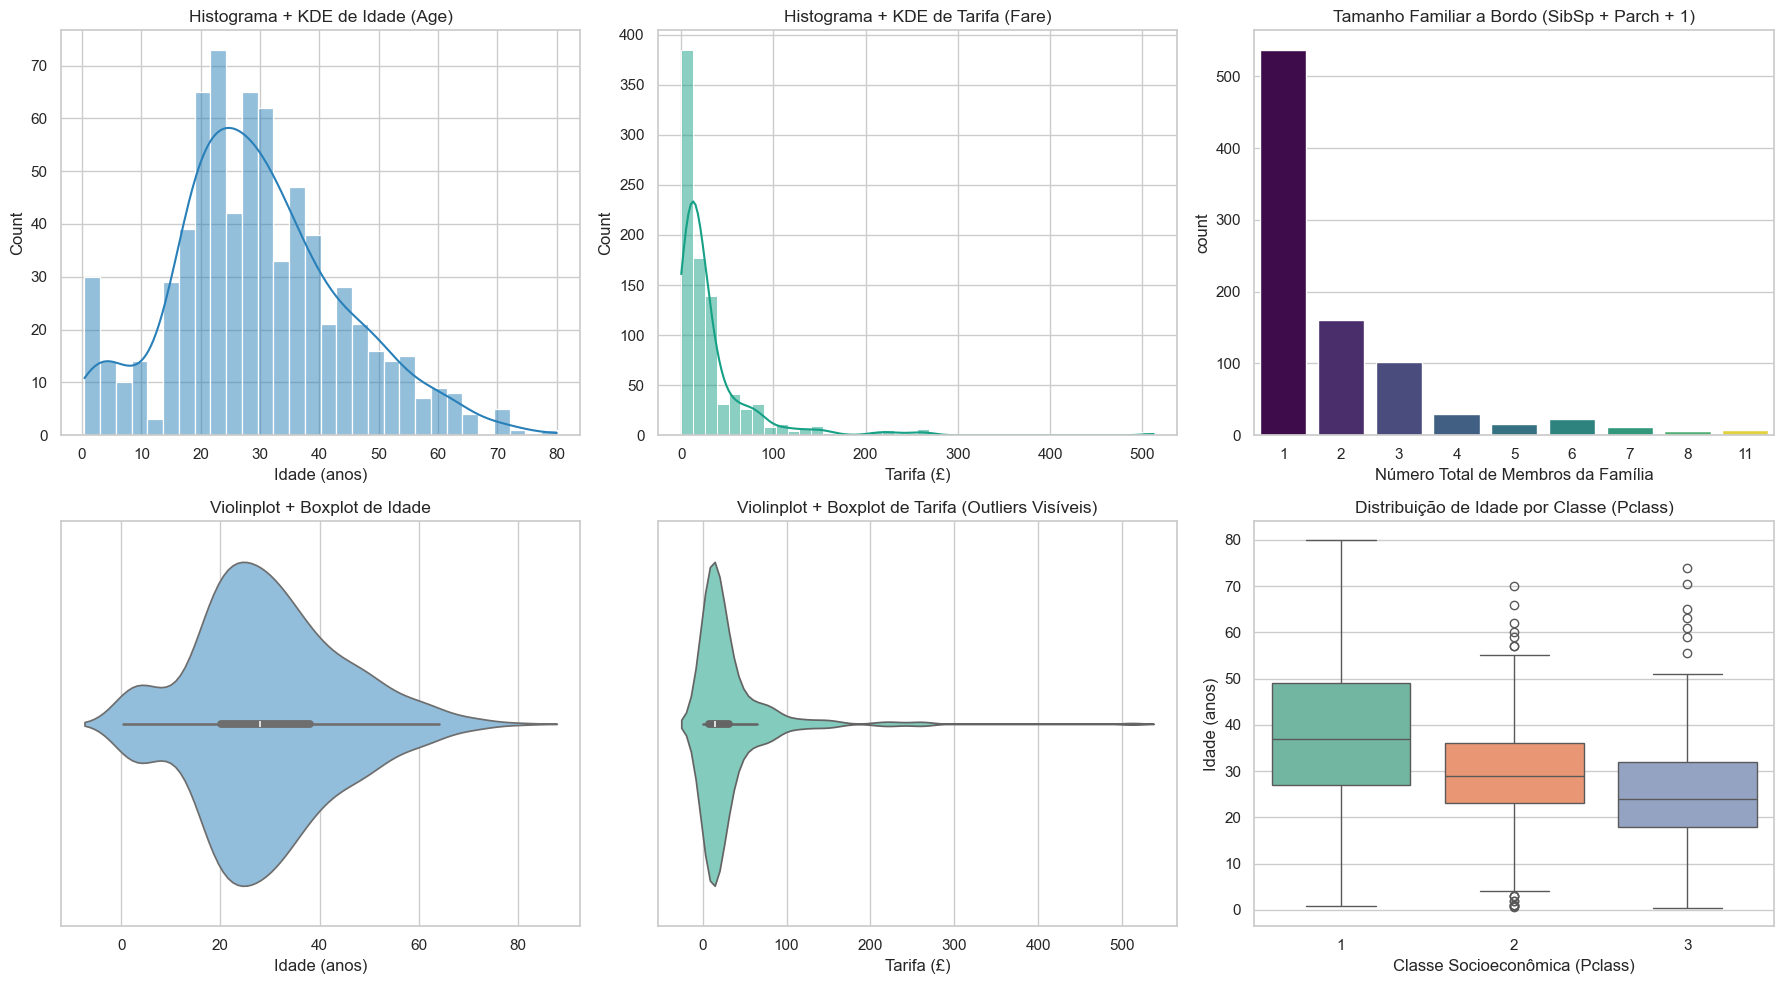

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Linha 1: Histogramas + KDE
sns.histplot(df["Age"].dropna(), kde=True, bins=30, color="#2980b9", ax=axes[0, 0])
axes[0, 0].set_title("Histograma + KDE de Idade (Age)", fontsize=12.5)
axes[0, 0].set_xlabel("Idade (anos)")

sns.histplot(df["Fare"], kde=True, bins=40, color="#16a085", ax=axes[0, 1])
axes[0, 1].set_title("Histograma + KDE de Tarifa (Fare)", fontsize=12.5)
axes[0, 1].set_xlabel("Tarifa (£)")

relatives_temp = df["SibSp"] + df["Parch"] + 1
sns.countplot(x=relatives_temp, hue=relatives_temp, palette="viridis", legend=False, ax=axes[0, 2])
axes[0, 2].set_title("Tamanho Familiar a Bordo (SibSp + Parch + 1)", fontsize=12.5)
axes[0, 2].set_xlabel("Número Total de Membros da Família")

# Linha 2: Violinplots + Boxplots internos
sns.violinplot(x=df["Age"], color="#85c1e9", inner="box", ax=axes[1, 0])
axes[1, 0].set_title("Violinplot + Boxplot de Idade", fontsize=12.5)
axes[1, 0].set_xlabel("Idade (anos)")

sns.violinplot(x=df["Fare"], color="#76d7c4", inner="box", ax=axes[1, 1])
axes[1, 1].set_title("Violinplot + Boxplot de Tarifa (Outliers Visíveis)", fontsize=12.5)
axes[1, 1].set_xlabel("Tarifa (£)")

sns.boxplot(data=df, x="Pclass", y="Age", hue="Pclass", palette="Set2", legend=False, ax=axes[1, 2])
axes[1, 2].set_title("Distribuição de Idade por Classe (Pclass)", fontsize=12.5)
axes[1, 2].set_xlabel("Classe Socioeconômica (Pclass)")
axes[1, 2].set_ylabel("Idade (anos)")

plt.tight_layout()
plt.show()


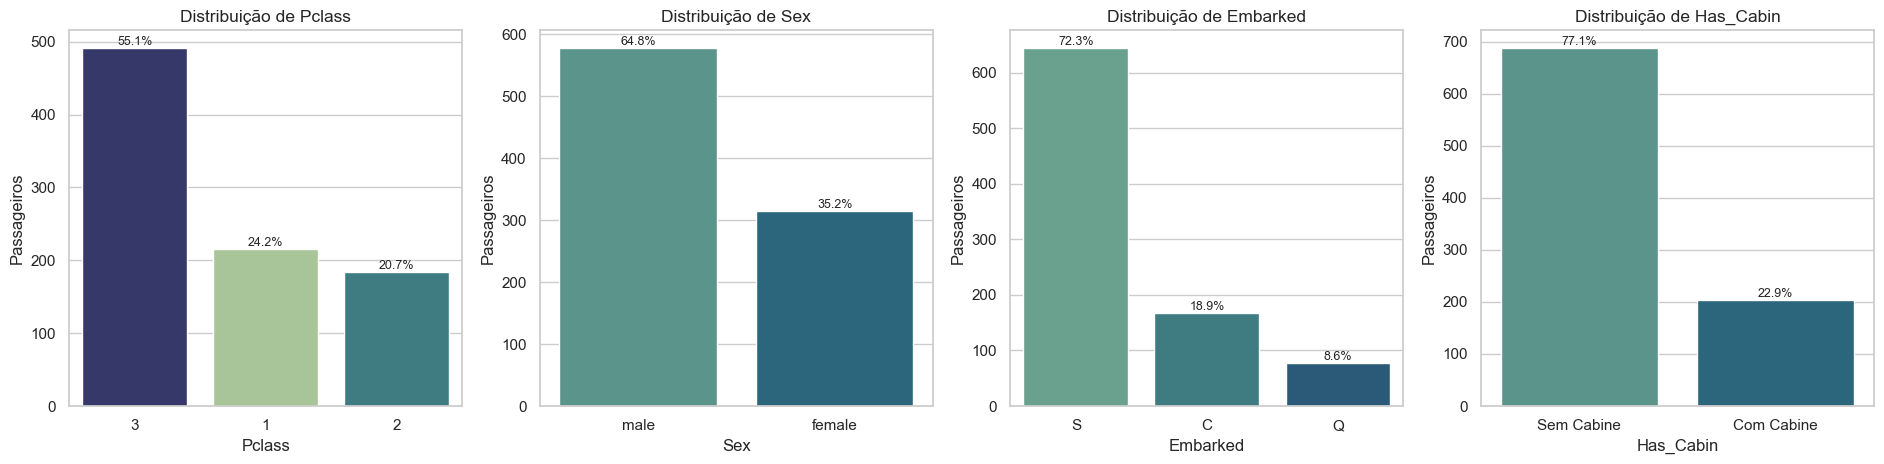

In [4]:
df_cat_eda = df.copy()
df_cat_eda["Has_Cabin"] = df_cat_eda["Cabin"].notna().map({False: "Sem Cabine", True: "Com Cabine"})

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
for i, col in enumerate(["Pclass", "Sex", "Embarked", "Has_Cabin"]):
    ordem = df_cat_eda[col].value_counts().index
    sns.countplot(data=df_cat_eda, x=col, hue=col, order=ordem, palette="crest", legend=False, ax=axes[i])
    axes[i].set_title(f"Distribuição de {col}", fontsize=12.5)
    axes[i].set_ylabel("Passageiros")
    for p in axes[i].patches:
        h = p.get_height()
        if h > 0:
            axes[i].annotate(
                f"{100 * h / len(df):.1f}%",
                (p.get_x() + p.get_width() / 2, h),
                ha="center",
                va="bottom",
                fontsize=9,
            )

plt.tight_layout()
plt.show()


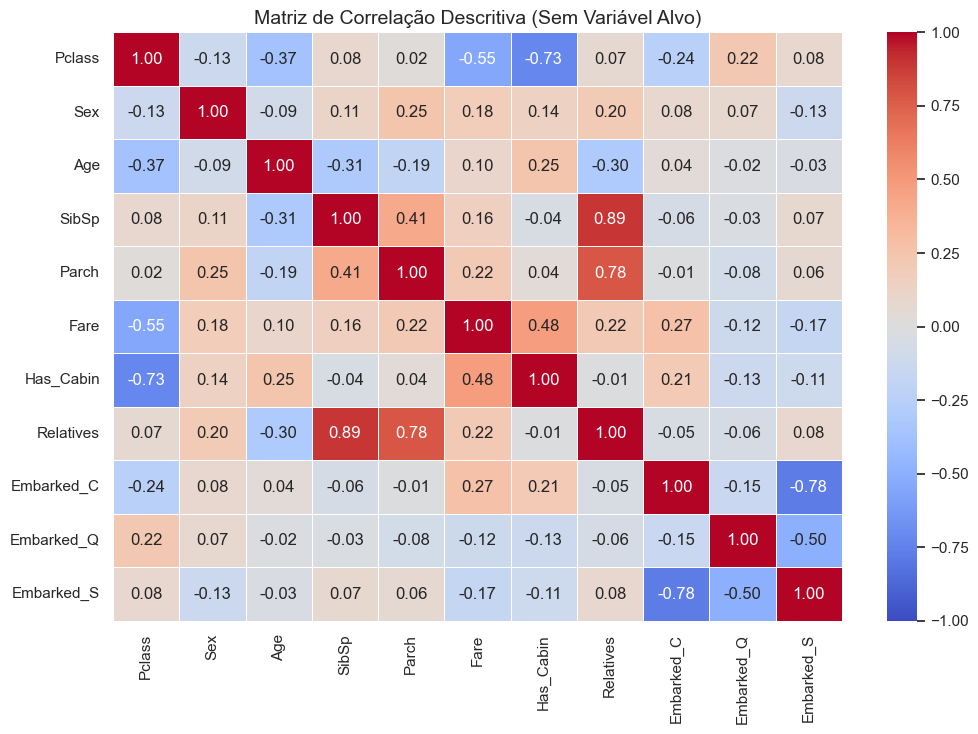

In [5]:
df_corr_unsup = df.copy()
df_corr_unsup["Has_Cabin"] = df_corr_unsup["Cabin"].notna().astype(int)
df_corr_unsup["Relatives"] = df_corr_unsup["SibSp"] + df_corr_unsup["Parch"] + 1
df_corr_unsup["Sex"] = df_corr_unsup["Sex"].map({"male": 0, "female": 1})
df_corr_unsup = pd.get_dummies(df_corr_unsup, columns=["Embarked"], prefix="Embarked", dtype=int)
df_corr_unsup = df_corr_unsup.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

plt.figure(figsize=(10.5, 7.5))
sns.heatmap(df_corr_unsup.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Matriz de Correlação Descritiva (Sem Variável Alvo)", fontsize=14)
plt.tight_layout()
plt.show()


**Insights da Análise Exploratória para Agrupamento:**
1. **Estrutura socioeconômica clara:** `Pclass`, `Has_Cabin` ($r = -0{,}73$ com `Pclass`) e `Fare` ($r = -0{,}55$ com `Pclass`) formam um eixo natural de estratificação entre passageiros de elite com cabine registrada e passageiros de 3ª classe.
2. **Diferença etária por classe:** o *boxplot* `Age` $\times$ `Pclass` mostra mediana de **37 anos na 1ª classe**, **29 anos na 2ª classe** e **24 anos na 3ª classe**, justificando imputar valores ausentes de `Age` pela mediana condicional de `(Sex, Pclass)`.
3. **Natureza mista dos dados:** temos variáveis contínuas/discretas (`Age`, `Fare`, `Relatives`) e variáveis categóricas/binárias (`Pclass`, `Sex`, `Has_Cabin`, `Embarked`). Isso motiva diretamente a comparação entre **K-Means** (distância euclidiana em espaço totalmente numérico normalizado), **K-Prototypes** (combinação nativa de distância euclidiana numérica + dissimilaridade de Hamming categórica ponderada por $\gamma$) e **DBSCAN** (agrupamento por densidade capaz de isolar *outliers* de tarifas extremas ou grandes famílias como ruído `-1`).


## 4. Pré-Processamento e Normalização para Algoritmos Baseados em Distância e Dados Mistos

Como algoritmos de agrupamento baseados em distância são altamente sensíveis à escala dos atributos, preparamos três visões alinhadas das **891 observações**:
1. **`df_unidades_reais`**: atributos tratados em suas unidades originais (`Age` em anos, `Fare` em £, `Pclass` 1/2/3, `Relatives` inteiro, `Sex`, `Has_Cabin`, `Embarked`) — usada para responder perguntas interpretáveis sobre cada cluster e extrair regras em escala humana.
2. **`X_dist_scaled` (para K-Means e DBSCAN)**: variáveis categóricas nominais codificadas via *One-Hot Encoding* (`Embarked_C`, `Embarked_Q`, `Embarked_S` — evitando criar uma ordem artificial entre portos!) e todos os atributos escalados para `[0.0, 1.0]` com `MinMaxScaler`.
3. **`X_kproto` (para K-Prototypes)**: variáveis numéricas (`Age`, `Fare`, `Relatives`) escaladas em `[0.0, 1.0]` combinadas diretamente com as variáveis categóricas (`Pclass`, `Sex`, `Has_Cabin`, `Embarked`) tratadas nativamente pelo algoritmo via parâmetro `categorical`.


In [6]:
df_limpo = df.copy()

# 1. Criação de Has_Cabin e Relatives
df_limpo["Has_Cabin"] = df_limpo["Cabin"].notna().astype(int)
df_limpo["Relatives"] = df_limpo["SibSp"] + df_limpo["Parch"] + 1

# 2. Imputação não supervisionada de Age (mediana por Sex e Pclass) e Embarked (moda)
medianas_idade = df_limpo.groupby(["Sex", "Pclass"])["Age"].median()
idade_map = df_limpo.set_index(["Sex", "Pclass"]).index.map(medianas_idade)
df_limpo["Age"] = df_limpo["Age"].fillna(pd.Series(idade_map, index=df_limpo.index)).fillna(df_limpo["Age"].median())
df_limpo["Embarked"] = df_limpo["Embarked"].fillna(df_limpo["Embarked"].mode()[0])

# Base interpretável em unidades reais
df_unidades_reais = pd.DataFrame({
    "Pclass": df_limpo["Pclass"].astype(int),
    "Sex": df_limpo["Sex"],
    "Sex_bin": df_limpo["Sex"].map({"male": 0, "female": 1}).astype(int),
    "Age": df_limpo["Age"].astype(float),
    "Fare": df_limpo["Fare"].astype(float),
    "Has_Cabin": df_limpo["Has_Cabin"].astype(int),
    "Embarked": df_limpo["Embarked"],
    "Relatives": df_limpo["Relatives"].astype(int),
})

# Visão 1: Espaço numérico normalizado [0, 1] para K-Means e DBSCAN
df_para_dist = pd.DataFrame({
    "Pclass": df_unidades_reais["Pclass"],
    "Sex": df_unidades_reais["Sex_bin"],
    "Age": df_unidades_reais["Age"],
    "Fare": df_unidades_reais["Fare"],
    "Has_Cabin": df_unidades_reais["Has_Cabin"],
    "Relatives": df_unidades_reais["Relatives"],
    "Embarked": df_unidades_reais["Embarked"],
})
df_para_dist = pd.get_dummies(df_para_dist, columns=["Embarked"], prefix="Embarked", dtype=int)

scaler_dist = MinMaxScaler()
X_dist_scaled = pd.DataFrame(
    scaler_dist.fit_transform(df_para_dist),
    columns=df_para_dist.columns,
    index=df_para_dist.index,
)

# Subconjunto puramente numérico/ordinal (para experimento comparativo no K-Means)
COLS_NUMERICAS_ORD = ["Pclass", "Age", "Fare", "Relatives"]
X_num_scaled = X_dist_scaled[COLS_NUMERICAS_ORD].copy()

# Visão 2: Dados mistos para K-Prototypes (numéricas em [0, 1] + categóricas nativas)
COLS_NUM_KPROTO = ["Age", "Fare", "Relatives"]
COLS_CAT_KPROTO = ["Pclass", "Sex", "Has_Cabin", "Embarked"]

scaler_num_kp = MinMaxScaler()
X_kproto = pd.DataFrame(
    scaler_num_kp.fit_transform(df_unidades_reais[COLS_NUM_KPROTO]),
    columns=COLS_NUM_KPROTO,
    index=df_unidades_reais.index,
)
for col_c in COLS_CAT_KPROTO:
    X_kproto[col_c] = df_unidades_reais[col_c].astype(str)

IDX_CAT_KPROTO = [X_kproto.columns.get_loc(c) for c in COLS_CAT_KPROTO]

print("Shape X_dist_scaled (K-Means / DBSCAN):", X_dist_scaled.shape)
print("Shape X_kproto (K-Prototypes):         ", X_kproto.shape, "| Índices categóricos:", IDX_CAT_KPROTO)
display(X_dist_scaled.head())


Shape X_dist_scaled (K-Means / DBSCAN): (891, 9)
Shape X_kproto (K-Prototypes):          (891, 7) | Índices categóricos: [3, 4, 5, 6]


,Pclass,Sex,Age,Fare,Has_Cabin,Relatives,Embarked_C,Embarked_Q,Embarked_S
0,1.0,0.0,0.271174,0.014151,0.0,0.1,0.0,0.0,1.0
1,0.0,1.0,0.472229,0.139136,1.0,0.1,1.0,0.0,0.0
2,1.0,1.0,0.321438,0.015469,0.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.434531,0.103644,1.0,0.1,0.0,0.0,1.0
4,1.0,0.0,0.434531,0.015713,0.0,0.0,0.0,0.0,1.0


## 5. Escolha do Melhor Número de Clusters ($k$) — As 5 Métricas e o Critério da Maioria

Conforme as diretrizes do projeto, implementamos e avaliamos conjuntamente as **cinco métricas** para $k \in \{2, 3, \dots, 10\}$:
1. **Elbow Method (Método do Cotovelo)**: ponto de inflexão (*knee*) na curva de inércia/custo detectado via `KneeLocator`.
2. **Calinski-Harabasz Index ($\uparrow$)**: razão entre dispersão inter-clusters e dispersão intra-cluster (maior é melhor).
3. **Davies-Bouldin Index ($\downarrow$)**: similaridade média de cada cluster com seu vizinho mais próximo (menor é melhor).
4. **Silhouette Score ($\uparrow$)**: coesão e separação média em $[-1, +1]$ (maior é melhor).
5. **BIC — Bayesian Information Criterion ($\uparrow$)**: formulação clássica de Pelleg & Moore (*X-Means*), que equilibra a verossimilhança esférica dos clusters com uma penalização proporcional ao número de parâmetros livres $p_k = (k - 1) + d \cdot k + 1$.

Para o **K-Prototypes**, além do custo misto nativo (`model.cost_`), calculamos a matriz de dissimilaridade mista exata de Huang ($d_{\text{num}}^2 + \gamma \cdot d_{\text{Hamming}}$) para avaliar o *Silhouette Score* respeitando a natureza mista dos atributos!


In [7]:
def bic_score_xmeans(X, labels):
    """
    BIC para agrupamento segundo Pelleg & Moore (2000) — X-Means.
    Valores maiores indicam melhor compromisso entre verossimilhança e parcimônia.
    """
    X_arr = np.asarray(X, dtype=float)
    lbl = np.asarray(labels)
    grupos = np.unique(lbl)
    n_points, n_dim = X_arr.shape
    k = len(grupos)

    if k <= 1 or n_points <= k:
        return -np.inf

    # Variância agrupada de máxima verossimilhança sob modelo Gaussiano esférico
    soma_quadrados = 0.0
    for g in grupos:
        pts = X_arr[lbl == g]
        centro = pts.mean(axis=0)
        soma_quadrados += np.sum((pts - centro) ** 2)

    variancia = max(soma_quadrados / (n_dim * (n_points - k)), 1e-9)

    log_lik = 0.0
    for g in grupos:
        rn = int(np.sum(lbl == g))
        if rn == 0:
            continue
        log_lik += (
            rn * math.log(rn)
            - rn * math.log(n_points)
            - (rn * n_dim / 2.0) * math.log(2.0 * math.pi * variancia)
            - (n_dim * (rn - 1) / 2.0)
        )

    n_params = (k - 1) + (n_dim * k) + 1
    return log_lik - 0.5 * n_params * math.log(n_points)


def matriz_distancia_mista(df_misto, cols_num, cols_cat, gamma):
    """Distância mista de Huang: Euclidiana quadrática/linear numérica + gamma * Hamming categórica."""
    X_num = df_misto[cols_num].to_numpy(dtype=float)
    X_cat = df_misto[cols_cat].to_numpy(dtype=str)

    dist_num_sq = pairwise_distances(X_num, metric="sqeuclidean")
    # Contagem de categorias diferentes entre cada par de amostras
    mismatch_cat = np.zeros_like(dist_num_sq)
    for j in range(X_cat.shape[1]):
        col = X_cat[:, j]
        mismatch_cat += (col[:, None] != col[None, :]).astype(float)

    return np.sqrt(dist_num_sq + gamma * mismatch_cat)


def escolher_k_por_maioria(votos_dict, Ks, scores_silhouette):
    votos_validos = [int(v) for v in votos_dict.values() if v is not None]
    contagem = Counter(votos_validos)
    max_freq = max(contagem.values())
    empatados = [k_cand for k_cand, freq in contagem.items() if freq == max_freq]
    if len(empatados) == 1:
        return empatados[0], contagem
    # Desempate técnico pelo maior Silhouette Score entre os mais votados
    ks_lista = list(Ks)
    melhor = max(empatados, key=lambda kc: scores_silhouette[ks_lista.index(kc)])
    return melhor, contagem


## 6. Algoritmo 1: K-Means (Atributos Numéricos/Ordinais Normalizados)

Como o K-Means baseia-se estritamente em médias aritméticas e distância euclidiana (que seriam distorcidas por cantos binários de variáveis *One-Hot*), aplicamos o K-Means sobre os atributos numéricos/ordinais normalizados (`Pclass`, `Age`, `Fare`, `Relatives`), reservando o tratamento simultâneo de variáveis categóricas nominais para o **K-Prototypes** (Seção 7) — além de comparar experimentalmente ambos os espaços na Seção 6.2.

### 6.1 Avaliação das 5 Métricas ($k = 2..10$) e Escolha por Maioria


,k,Inertia (Elbow),Calinski-Harabasz,Silhouette,Davies-Bouldin,BIC
0,2,76.50,1573.98,0.5874,0.6583,1141.24
1,3,49.03,1475.47,0.5676,0.7176,1641.18
2,4,33.78,1559.44,0.6085,0.6770,2109.63
3,5,29.17,1387.94,0.5615,0.8607,2204.45
4,6,25.51,1293.61,0.4787,0.8788,2230.16
5,7,22.49,1241.02,0.4467,0.9257,2333.42
6,8,19.81,1223.49,0.4601,0.9190,2490.70
7,9,17.70,1209.77,0.4570,0.9317,2526.35
8,10,15.86,1210.15,0.4759,0.9005,2642.29


Votos por métrica (K-Means): {'Elbow': 4, 'Calinski-Harabasz (max)': 2, 'Silhouette (max)': 4, 'Davies-Bouldin (min)': 2, 'BIC (max)': 10}
Contagem de votos: {4: 2, 2: 2, 10: 1} -> k escolhido para K-Means = 4


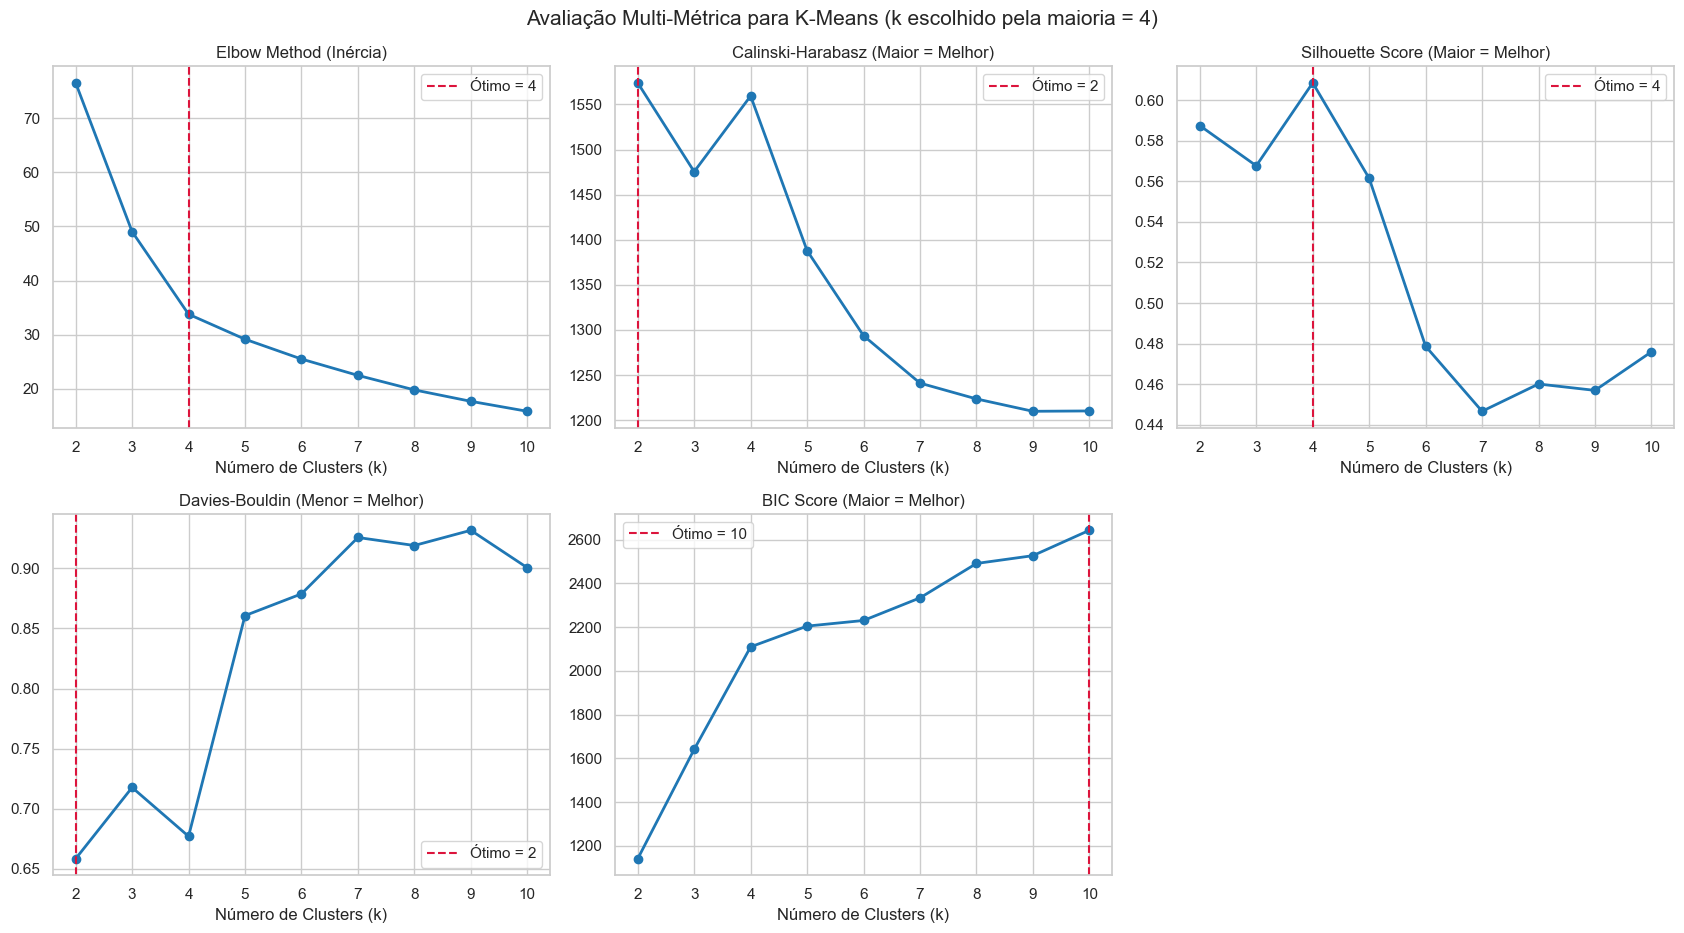

In [8]:
Ks = range(2, 11)
km_inertia, km_ch, km_sil, km_db, km_bic = [], [], [], [], []

for k in Ks:
    km_temp = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=RANDOM_STATE)
    lbl = km_temp.fit_predict(X_num_scaled)

    km_inertia.append(km_temp.inertia_)
    km_ch.append(calinski_harabasz_score(X_num_scaled, lbl))
    km_sil.append(silhouette_score(X_num_scaled, lbl))
    km_db.append(davies_bouldin_score(X_num_scaled, lbl))
    km_bic.append(bic_score_xmeans(X_num_scaled, lbl))

knee_km = KneeLocator(list(Ks), km_inertia, curve="convex", direction="decreasing").elbow
votos_kmeans = {
    "Elbow": int(knee_km) if knee_km is not None else None,
    "Calinski-Harabasz (max)": list(Ks)[int(np.argmax(km_ch))],
    "Silhouette (max)": list(Ks)[int(np.argmax(km_sil))],
    "Davies-Bouldin (min)": list(Ks)[int(np.argmin(km_db))],
    "BIC (max)": list(Ks)[int(np.argmax(km_bic))],
}

best_k_kmeans, placar_km = escolher_k_por_maioria(votos_kmeans, Ks, km_sil)

df_metricas_km = pd.DataFrame({
    "k": list(Ks),
    "Inertia (Elbow)": np.round(km_inertia, 2),
    "Calinski-Harabasz": np.round(km_ch, 2),
    "Silhouette": np.round(km_sil, 4),
    "Davies-Bouldin": np.round(km_db, 4),
    "BIC": np.round(km_bic, 2),
})
display(df_metricas_km)
print("Votos por métrica (K-Means):", votos_kmeans)
print(f"Contagem de votos: {dict(placar_km)} -> k escolhido para K-Means = {best_k_kmeans}")

fig, axs = plt.subplots(2, 3, figsize=(17, 9.5))
axs = axs.ravel()
pares_plot_km = [
    ("Elbow Method (Inércia)", km_inertia, votos_kmeans["Elbow"]),
    ("Calinski-Harabasz (Maior = Melhor)", km_ch, votos_kmeans["Calinski-Harabasz (max)"]),
    ("Silhouette Score (Maior = Melhor)", km_sil, votos_kmeans["Silhouette (max)"]),
    ("Davies-Bouldin (Menor = Melhor)", km_db, votos_kmeans["Davies-Bouldin (min)"]),
    ("BIC Score (Maior = Melhor)", km_bic, votos_kmeans["BIC (max)"]),
]
for idx, (titulo, serie, k_otimo) in enumerate(pares_plot_km):
    axs[idx].plot(list(Ks), serie, marker="o", linewidth=2, color="#1f77b4")
    if k_otimo is not None:
        axs[idx].axvline(k_otimo, color="crimson", linestyle="--", label=f"Ótimo = {k_otimo}")
        axs[idx].legend()
    axs[idx].set_title(titulo, fontsize=12)
    axs[idx].set_xlabel("Número de Clusters (k)")
    axs[idx].set_xticks(list(Ks))

axs[5].set_visible(False)
plt.suptitle(f"Avaliação Multi-Métrica para K-Means (k escolhido pela maioria = {best_k_kmeans})", fontsize=15)
plt.tight_layout()
plt.show()


### 6.2 Experimentos de Refinamento no K-Means (Espaço Numérico vs. One-Hot e Inicialização)
Comparamos experimentalmente o K-Means variando a inicialização (`k-means++` vs. `random`), valores candidatos de $k$ e a representação de atributos (`X_num_scaled` vs. `X_dist_scaled` com variáveis categóricas *One-Hot*), evidenciando por que variáveis nominais favorecem o **K-Prototypes** na seção seguinte.


In [9]:
exp_kmeans_rows = []
for desc_espaco, matriz in [("Numéricas/Ordinais (4 cols)", X_num_scaled), ("Completa One-Hot Normalizada (9 cols)", X_dist_scaled)]:
    for k_teste in sorted({3, 4, 5, best_k_kmeans}):
        for init_m in ["k-means++", "random"]:
            mod = KMeans(n_clusters=k_teste, init=init_m, n_init=20, random_state=RANDOM_STATE)
            l_tmp = mod.fit_predict(matriz)
            exp_kmeans_rows.append({
                "Espaço de Atributos": desc_espaco,
                "k": k_teste,
                "Inicialização": init_m,
                "Inércia": round(mod.inertia_, 2),
                "Silhouette": round(silhouette_score(matriz, l_tmp), 4),
                "Davies-Bouldin": round(davies_bouldin_score(matriz, l_tmp), 4),
                "Calinski-Harabasz": round(calinski_harabasz_score(matriz, l_tmp), 2),
            })

display(pd.DataFrame(exp_kmeans_rows))

modelo_kmeans = KMeans(n_clusters=best_k_kmeans, init="k-means++", n_init=20, random_state=RANDOM_STATE)
labels_kmeans = modelo_kmeans.fit_predict(X_num_scaled)
print(f"Distribuição de passageiros por cluster no K-Means (k={best_k_kmeans}):")
print(pd.Series(labels_kmeans).value_counts().sort_index().rename_axis("Cluster").to_frame("Passageiros"))


,Espaço de Atributos,k,Inicialização,Inércia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Numéricas/Ordinais (4 cols),3,k-means++,49.03,0.5676,0.7176,1475.47
1,Numéricas/Ordinais (4 cols),3,random,49.03,0.5676,0.7176,1475.47
2,Numéricas/Ordinais (4 cols),4,k-means++,33.78,0.6085,0.6770,1559.44
3,Numéricas/Ordinais (4 cols),4,random,33.78,0.6085,0.6770,1559.44
4,Numéricas/Ordinais (4 cols),5,k-means++,29.17,0.5615,0.8607,1387.94
5,Numéricas/Ordinais (4 cols),5,random,29.17,0.5615,0.8607,1387.94
6,Completa One-Hot Normalizada (9 cols),3,k-means++,501.46,0.4311,1.2117,403.24
7,Completa One-Hot Normalizada (9 cols),3,random,501.46,0.4311,1.2117,403.24
8,Completa One-Hot Normalizada (9 cols),4,k-means++,392.64,0.4456,0.9973,424.88
9,Completa One-Hot Normalizada (9 cols),4,random,391.73,0.4446,1.0863,426.57


Distribuição de passageiros por cluster no K-Means (k=4):
         Passageiros
Cluster             
0                 58
1                216
2                184
3                433


## 7. Algoritmo 2: K-Prototypes (Dados Mistos: Numéricos + Categóricos)

O **K-Prototypes** evita distorções da distância euclidiana em variáveis categóricas ao minimizar a função custo mista:
$$E = \sum_{l=1}^{k} \sum_{x_i \in C_l} \left( \| x_i^{\text{num}} - \mu_l^{\text{num}} \|_2^2 + \gamma \sum_{j \in \text{cat}} \delta(x_{i,j}^{\text{cat}}, \mu_{l,j}^{\text{cat}}) \right)$$
onde $\gamma$ controla o peso relativo dos atributos categóricos frente aos numéricos.

### 7.1 Experimentos com o Hiperparâmetro $\gamma$ (Peso Categórico) e Seleção de $k$ pelas 5 Métricas
Primeiro exploramos diferentes valores de $\gamma \in \{0{,}10,\; 0{,}25,\; 0{,}50,\; 0{,}75,\; 1{,}00\}$ e, em seguida, aplicamos as 5 métricas sobre $k = 2..10$.


In [10]:
linhas_gamma = []
for g_val in [0.10, 0.25, 0.50, 0.75, 1.00]:
    D_g = matriz_distancia_mista(X_kproto, COLS_NUM_KPROTO, COLS_CAT_KPROTO, gamma=g_val)
    kp_g = KPrototypes(n_clusters=4, gamma=g_val, init="Cao", n_init=5, random_state=RANDOM_STATE)
    lbl_g = kp_g.fit_predict(X_kproto.to_numpy(), categorical=IDX_CAT_KPROTO)
    sil_misto = silhouette_score(D_g, lbl_g, metric="precomputed")
    linhas_gamma.append({
        "gamma": g_val,
        "Custo K-Prototypes": round(kp_g.cost_, 2),
        "Silhouette Misto (k=4)": round(sil_misto, 4),
        "Menor Cluster": int(pd.Series(lbl_g).value_counts().min()),
        "Maior Cluster": int(pd.Series(lbl_g).value_counts().max()),
    })

df_gamma = pd.DataFrame(linhas_gamma)
display(df_gamma)
melhor_gamma = float(df_gamma.loc[df_gamma["Silhouette Misto (k=4)"].idxmax(), "gamma"])
print(f"Melhor gamma selecionado pela coesão/separação mista: gamma = {melhor_gamma}")


,gamma,Custo K-Prototypes,Silhouette Misto (k=4),Menor Cluster,Maior Cluster
0,0.10,94.80,0.2658,127,386
1,0.25,186.55,0.2701,86,511
2,0.50,325.30,0.2856,86,511
3,0.75,464.05,0.2936,86,511
4,1.00,602.80,0.2987,86,511


Melhor gamma selecionado pela coesão/separação mista: gamma = 1.0


,k,Cost (Elbow),Calinski-Harabasz,Silhouette Misto,Davies-Bouldin,BIC
0,2,836.84,306.43,0.3497,1.4407,-2236.51
1,3,687.77,216.74,0.2895,1.8371,-2233.58
2,4,602.80,218.84,0.2987,1.4120,-1783.39
3,5,500.50,195.66,0.3474,1.4599,-1743.84
4,6,358.35,194.01,0.4461,1.7283,-1551.95
5,7,318.45,231.50,0.4652,1.4955,-951.17
6,8,285.27,238.02,0.4953,1.4091,-603.81
7,9,263.01,237.21,0.5084,1.1746,-304.27
8,10,223.19,271.37,0.5469,1.2086,282.05


Votos por métrica (K-Prototypes): {'Elbow (Cost)': 6, 'Calinski-Harabasz (max)': 2, 'Silhouette Misto (max)': 10, 'Davies-Bouldin (min)': 9, 'BIC (max)': 10}
Contagem de votos: {6: 1, 2: 1, 10: 2, 9: 1} -> k escolhido para K-Prototypes = 10


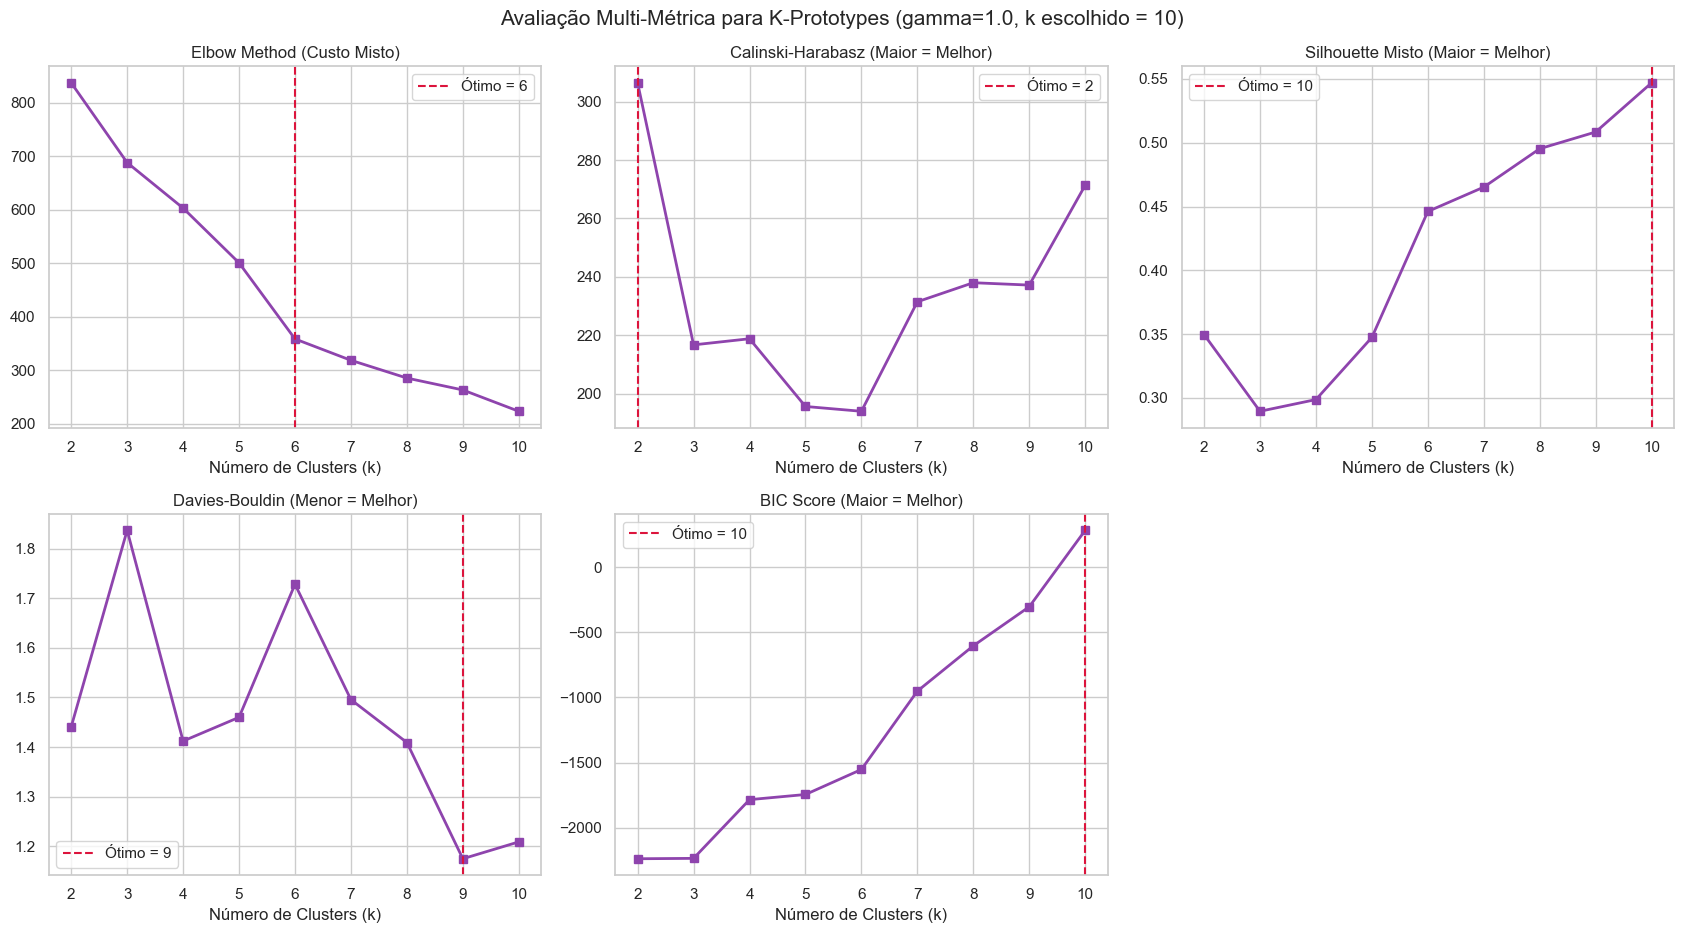

Distribuição de passageiros por cluster no K-Prototypes (k=10):
         Passageiros
Cluster             
0                264
1                 15
2                 76
3                112
4                 54
5                 46
6                 39
7                 78
8                 97
9                110


In [11]:
D_mista_otima = matriz_distancia_mista(X_kproto, COLS_NUM_KPROTO, COLS_CAT_KPROTO, gamma=melhor_gamma)
kp_cost, kp_ch, kp_sil, kp_db, kp_bic = [], [], [], [], []
modelos_kp_por_k = {}

for k in Ks:
    kp_m = KPrototypes(n_clusters=k, gamma=melhor_gamma, init="Cao", n_init=5, random_state=RANDOM_STATE)
    lbl_kp = kp_m.fit_predict(X_kproto.to_numpy(), categorical=IDX_CAT_KPROTO)
    modelos_kp_por_k[k] = (kp_m, lbl_kp)

    kp_cost.append(kp_m.cost_)
    kp_sil.append(silhouette_score(D_mista_otima, lbl_kp, metric="precomputed"))
    kp_ch.append(calinski_harabasz_score(X_dist_scaled, lbl_kp))
    kp_db.append(davies_bouldin_score(X_dist_scaled, lbl_kp))
    kp_bic.append(bic_score_xmeans(X_dist_scaled, lbl_kp))

knee_kp = KneeLocator(list(Ks), kp_cost, curve="convex", direction="decreasing").elbow
votos_kproto = {
    "Elbow (Cost)": int(knee_kp) if knee_kp is not None else None,
    "Calinski-Harabasz (max)": list(Ks)[int(np.argmax(kp_ch))],
    "Silhouette Misto (max)": list(Ks)[int(np.argmax(kp_sil))],
    "Davies-Bouldin (min)": list(Ks)[int(np.argmin(kp_db))],
    "BIC (max)": list(Ks)[int(np.argmax(kp_bic))],
}

best_k_kproto, placar_kp = escolher_k_por_maioria(votos_kproto, Ks, kp_sil)
modelo_kproto, labels_kproto = modelos_kp_por_k[best_k_kproto]

df_metricas_kp = pd.DataFrame({
    "k": list(Ks),
    "Cost (Elbow)": np.round(kp_cost, 2),
    "Calinski-Harabasz": np.round(kp_ch, 2),
    "Silhouette Misto": np.round(kp_sil, 4),
    "Davies-Bouldin": np.round(kp_db, 4),
    "BIC": np.round(kp_bic, 2),
})
display(df_metricas_kp)
print("Votos por métrica (K-Prototypes):", votos_kproto)
print(f"Contagem de votos: {dict(placar_kp)} -> k escolhido para K-Prototypes = {best_k_kproto}")

fig, axs = plt.subplots(2, 3, figsize=(17, 9.5))
axs = axs.ravel()
pares_plot_kp = [
    ("Elbow Method (Custo Misto)", kp_cost, votos_kproto["Elbow (Cost)"]),
    ("Calinski-Harabasz (Maior = Melhor)", kp_ch, votos_kproto["Calinski-Harabasz (max)"]),
    ("Silhouette Misto (Maior = Melhor)", kp_sil, votos_kproto["Silhouette Misto (max)"]),
    ("Davies-Bouldin (Menor = Melhor)", kp_db, votos_kproto["Davies-Bouldin (min)"]),
    ("BIC Score (Maior = Melhor)", kp_bic, votos_kproto["BIC (max)"]),
]
for idx, (titulo, serie, k_otimo) in enumerate(pares_plot_kp):
    axs[idx].plot(list(Ks), serie, marker="s", linewidth=2, color="#8e44ad")
    if k_otimo is not None:
        axs[idx].axvline(k_otimo, color="crimson", linestyle="--", label=f"Ótimo = {k_otimo}")
        axs[idx].legend()
    axs[idx].set_title(titulo, fontsize=12)
    axs[idx].set_xlabel("Número de Clusters (k)")
    axs[idx].set_xticks(list(Ks))

axs[5].set_visible(False)
plt.suptitle(f"Avaliação Multi-Métrica para K-Prototypes (gamma={melhor_gamma}, k escolhido = {best_k_kproto})", fontsize=15)
plt.tight_layout()
plt.show()

print(f"Distribuição de passageiros por cluster no K-Prototypes (k={best_k_kproto}):")
print(pd.Series(labels_kproto).value_counts().sort_index().rename_axis("Cluster").to_frame("Passageiros"))


## 8. Algoritmo 3: DBSCAN (Agrupamento Baseado em Densidade)

Diferente de K-Means e K-Prototypes, o **DBSCAN** não exige especificar $k$ previamente, consegue encontrar agrupamentos de formato arbitrário e isola observações atípicas em regiões esparsas como **ruído (`Cluster = -1`)**.

### 8.1 Gráfico *k-Distance* e Experimentos Sistemáticos com `eps` e `min_samples`
Para dados com $d = 9$ dimensões normalizadas, uma heurística clássica sugere testar `min_samples` em torno de $d + 1 = 10$ a $2d = 18$, utilizando o **cotovelo do gráfico *k-distance*** para localizar a faixa de transição de densidade de `eps`.


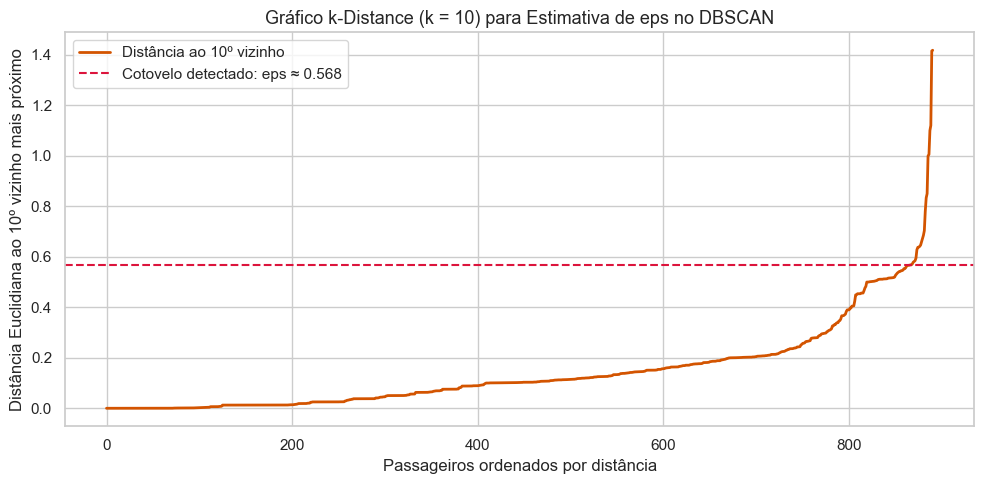

In [12]:
k_vizinhos = 10
nn = NearestNeighbors(n_neighbors=k_vizinhos)
nn.fit(X_dist_scaled)
distancias_nn, _ = nn.kneighbors(X_dist_scaled)
dist_ordenadas = np.sort(distancias_nn[:, k_vizinhos - 1])

knee_db = KneeLocator(
    range(len(dist_ordenadas)), dist_ordenadas, curve="convex", direction="increasing"
)
eps_sugerido = float(dist_ordenadas[knee_db.knee]) if knee_db.knee is not None else 0.35

plt.figure(figsize=(10, 5))
plt.plot(dist_ordenadas, linewidth=2, color="#d35400", label=f"Distância ao {k_vizinhos}º vizinho")
plt.axhline(eps_sugerido, color="crimson", linestyle="--", label=f"Cotovelo detectado: eps ≈ {eps_sugerido:.3f}")
plt.title(f"Gráfico k-Distance (k = {k_vizinhos}) para Estimativa de eps no DBSCAN", fontsize=13)
plt.xlabel("Passageiros ordenados por distância")
plt.ylabel(f"Distância Euclidiana ao {k_vizinhos}º vizinho mais próximo")
plt.legend()
plt.tight_layout()
plt.show()


In [13]:
experimentos_dbscan = []
for eps_cand in [0.25, 0.35, 0.45, 0.55, 0.65]:
    for ms_cand in [8, 12, 15, 18]:
        db_tmp = DBSCAN(eps=eps_cand, min_samples=ms_cand)
        lbl_db = db_tmp.fit_predict(X_dist_scaled)

        mascara_validos = lbl_db != -1
        grupos_validos = set(lbl_db[mascara_validos])
        n_clusters_db = len(grupos_validos)
        perc_ruido = (1.0 - mascara_validos.mean()) * 100

        if n_clusters_db >= 2 and mascara_validos.sum() > n_clusters_db:
            sil_sem_ruido = silhouette_score(X_dist_scaled[mascara_validos], lbl_db[mascara_validos])
            dbi_sem_ruido = davies_bouldin_score(X_dist_scaled[mascara_validos], lbl_db[mascara_validos])
        else:
            sil_sem_ruido = np.nan
            dbi_sem_ruido = np.nan

        experimentos_dbscan.append({
            "eps": eps_cand,
            "min_samples": ms_cand,
            "Nº Clusters (sem ruído)": n_clusters_db,
            "Pontos de Ruído (-1)": int((~mascara_validos).sum()),
            "% Ruído": round(perc_ruido, 2),
            "Silhouette (sem ruído)": round(sil_sem_ruido, 4) if not np.isnan(sil_sem_ruido) else np.nan,
            "Davies-Bouldin (sem ruído)": round(dbi_sem_ruido, 4) if not np.isnan(dbi_sem_ruido) else np.nan,
        })

df_exp_dbscan = pd.DataFrame(experimentos_dbscan)
# Filtramos configurações equilibradas (entre 3 e 10 clusters e menos de 20% de ruído)
candidatos_equilibrados = df_exp_dbscan[
    (df_exp_dbscan["Nº Clusters (sem ruído)"].between(3, 10)) & (df_exp_dbscan["% Ruído"].between(1.0, 20.0))
].sort_values(by="Silhouette (sem ruído)", ascending=False)

display(candidatos_equilibrados.head(10))

melhor_cfg_db = candidatos_equilibrados.iloc[0]
BEST_EPS = float(melhor_cfg_db["eps"])
BEST_MIN_SAMPLES = int(melhor_cfg_db["min_samples"])

modelo_dbscan = DBSCAN(eps=BEST_EPS, min_samples=BEST_MIN_SAMPLES)
labels_dbscan = modelo_dbscan.fit_predict(X_dist_scaled)

print(f"Configuração DBSCAN selecionada: eps={BEST_EPS}, min_samples={BEST_MIN_SAMPLES}")
print("Contagem por grupo no DBSCAN (-1 representa pontos de ruído/outliers):")
print(pd.Series(labels_dbscan).value_counts().sort_index().rename_axis("Cluster").to_frame("Passageiros"))


,eps,min_samples,Nº Clusters (sem ruído),Pontos de Ruído (-1),% Ruído,Silhouette (sem ruído),Davies-Bouldin (sem ruído)
14,0.55,15,10,11,1.23,0.6315,0.5679
15,0.55,18,10,11,1.23,0.6315,0.5679


Configuração DBSCAN selecionada: eps=0.55, min_samples=15
Contagem por grupo no DBSCAN (-1 representa pontos de ruído/outliers):
         Passageiros
Cluster             
-1                11
 0               368
 1                36
 2               147
 3                56
 4                39
 5                72
 6                33
 7                34
 8                63
 9                32


## 9. Avaliação Geométrica: Distâncias Intra-Cluster, Inter-Clusters e Comparação dos 3 Algoritmos

Calculamos para **todos os clusters formados** em cada um dos três algoritmos:
* **Distância Média Intra-Cluster (Coesão $\downarrow$)**: distância média das observações ao centroide/protótipo de seu próprio grupo.
* **Distâncias Inter-Clusters (Separação $\uparrow$)**: matriz de distâncias par-a-par entre os centros dos clusters (exibida em *heatmaps*), destacando a menor distância entre dois grupos distintos (`Inter Mínima`) e o índice de separação relativa (`Inter Mínima / Intra Média`).


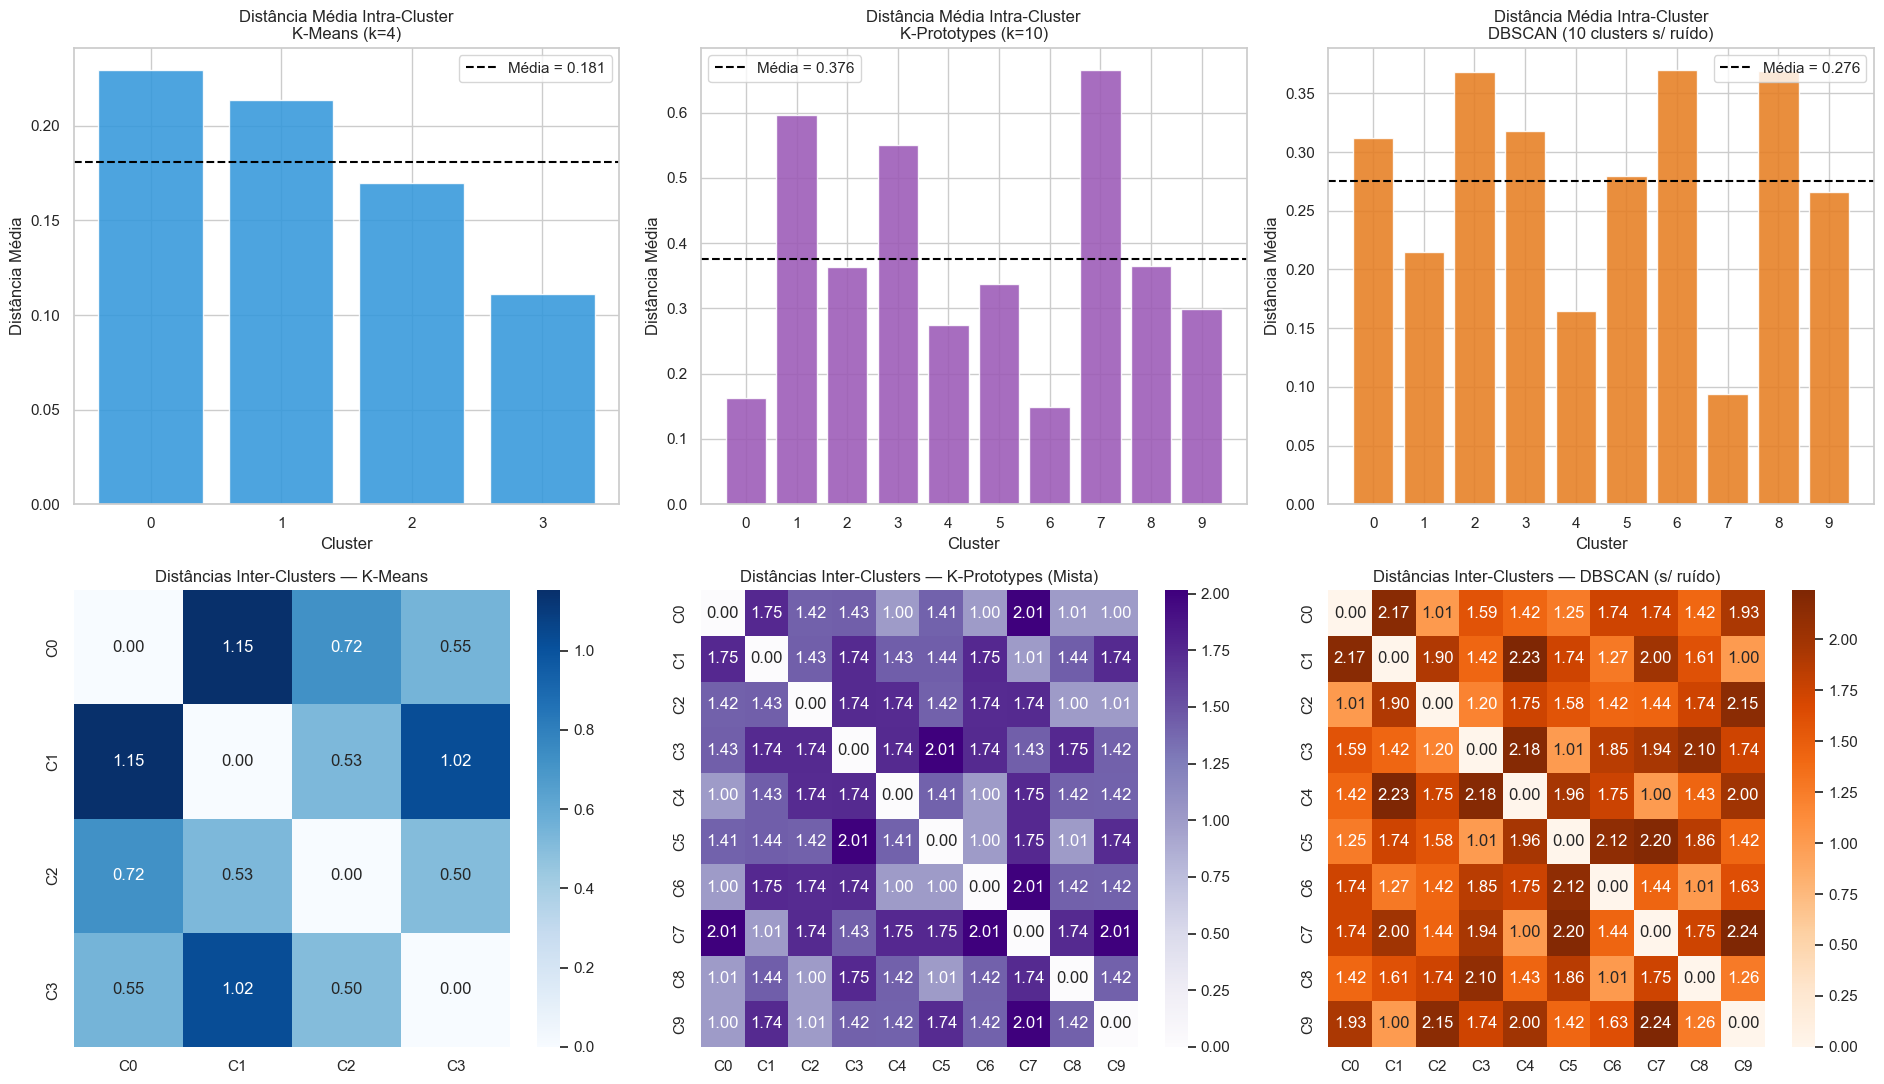

,Algoritmo,Nº Clusters,% Ruído,Silhouette (Espaço Nativo),Calinski-Harabasz,Davies-Bouldin,Intra Média,Inter Mínima,Razão Inter_Min / Intra_Med
0,K-Means (Espaço Numérico),4,0.00,0.6085,1559.44,0.6770,0.1811,0.5043,2.78
1,"K-Prototypes (gamma=1.0, Misto)",10,0.00,0.5469,271.37,1.2086,0.3764,1.0000,2.66
2,"DBSCAN (eps=0.55, ms=15)",10,1.23,0.6315,711.08,0.5679,0.2755,1.0019,3.64


In [14]:
def calcular_intra_inter_euclidiano(X_df, labels, ignorar_ruido=False):
    X_arr = X_df.to_numpy(dtype=float)
    grupos = sorted([g for g in np.unique(labels) if not (ignorar_ruido and g == -1)])
    centros = np.vstack([X_arr[labels == g].mean(axis=0) for g in grupos])

    intra_por_grupo = {}
    for idx_g, g in enumerate(grupos):
        pts = X_arr[labels == g]
        dists = np.linalg.norm(pts - centros[idx_g], axis=1)
        intra_por_grupo[g] = float(dists.mean())

    inter_mat = pairwise_distances(centros, metric="euclidean")
    inter_sem_diag = inter_mat.copy()
    np.fill_diagonal(inter_sem_diag, np.inf)
    return grupos, intra_por_grupo, inter_mat, float(np.min(inter_sem_diag))


def calcular_intra_inter_misto(D_precomp, labels):
    grupos = sorted(np.unique(labels))
    intra_por_grupo = {}
    medoides = []
    for g in grupos:
        idx_pts = np.where(labels == g)[0]
        sub_D = D_precomp[np.ix_(idx_pts, idx_pts)]
        medoide_local = idx_pts[int(np.argmin(sub_D.mean(axis=1)))]
        medoides.append(medoide_local)
        intra_por_grupo[g] = float(D_precomp[idx_pts, medoide_local].mean())

    inter_mat = D_precomp[np.ix_(medoides, medoides)]
    inter_sem_diag = inter_mat.copy()
    np.fill_diagonal(inter_sem_diag, np.inf)
    return grupos, intra_por_grupo, inter_mat, float(np.min(inter_sem_diag))


grupos_km, intra_km, inter_km, min_inter_km = calcular_intra_inter_euclidiano(X_num_scaled, labels_kmeans)
grupos_kp, intra_kp, inter_kp, min_inter_kp = calcular_intra_inter_misto(D_mista_otima, labels_kproto)
grupos_db, intra_db, inter_db, min_inter_db = calcular_intra_inter_euclidiano(X_dist_scaled, labels_dbscan, ignorar_ruido=True)

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Linha 1: Barras de Distância Intra-Cluster
for col_i, (titulo, grps, intra_d, cor) in enumerate([
    (f"K-Means (k={best_k_kmeans})", grupos_km, intra_km, "#3498db"),
    (f"K-Prototypes (k={best_k_kproto})", grupos_kp, intra_kp, "#9b59b6"),
    (f"DBSCAN ({len(grupos_db)} clusters s/ ruído)", grupos_db, intra_db, "#e67e22"),
]):
    vals = [intra_d[g] for g in grps]
    axes[0, col_i].bar([str(g) for g in grps], vals, color=cor, alpha=0.88)
    axes[0, col_i].axhline(np.mean(vals), color="black", linestyle="--", label=f"Média = {np.mean(vals):.3f}")
    axes[0, col_i].set_title(f"Distância Média Intra-Cluster\n{titulo}", fontsize=12)
    axes[0, col_i].set_xlabel("Cluster")
    axes[0, col_i].set_ylabel("Distância Média")
    axes[0, col_i].legend()

# Linha 2: Heatmaps de Distância Inter-Cluster
for col_i, (titulo, grps, inter_m, cmap_n) in enumerate([
    ("K-Means", grupos_km, inter_km, "Blues"),
    ("K-Prototypes (Mista)", grupos_kp, inter_kp, "Purples"),
    ("DBSCAN (s/ ruído)", grupos_db, inter_db, "Oranges"),
]):
    sns.heatmap(
        inter_m,
        annot=True,
        fmt=".2f",
        cmap=cmap_n,
        xticklabels=[f"C{g}" for g in grps],
        yticklabels=[f"C{g}" for g in grps],
        ax=axes[1, col_i],
    )
    axes[1, col_i].set_title(f"Distâncias Inter-Clusters — {titulo}", fontsize=12)

plt.tight_layout()
plt.show()

mask_db_val = labels_dbscan != -1
df_comp_algoritmos = pd.DataFrame([
    {
        "Algoritmo": "K-Means (Espaço Numérico)",
        "Nº Clusters": len(grupos_km),
        "% Ruído": 0.0,
        "Silhouette (Espaço Nativo)": round(silhouette_score(X_num_scaled, labels_kmeans), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_num_scaled, labels_kmeans), 2),
        "Davies-Bouldin": round(davies_bouldin_score(X_num_scaled, labels_kmeans), 4),
        "Intra Média": round(float(np.mean(list(intra_km.values()))), 4),
        "Inter Mínima": round(min_inter_km, 4),
        "Razão Inter_Min / Intra_Med": round(min_inter_km / float(np.mean(list(intra_km.values()))), 2),
    },
    {
        "Algoritmo": f"K-Prototypes (gamma={melhor_gamma}, Misto)",
        "Nº Clusters": len(grupos_kp),
        "% Ruído": 0.0,
        "Silhouette (Espaço Nativo)": round(silhouette_score(D_mista_otima, labels_kproto, metric="precomputed"), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_dist_scaled, labels_kproto), 2),
        "Davies-Bouldin": round(davies_bouldin_score(X_dist_scaled, labels_kproto), 4),
        "Intra Média": round(float(np.mean(list(intra_kp.values()))), 4),
        "Inter Mínima": round(min_inter_kp, 4),
        "Razão Inter_Min / Intra_Med": round(min_inter_kp / float(np.mean(list(intra_kp.values()))), 2),
    },
    {
        "Algoritmo": f"DBSCAN (eps={BEST_EPS}, ms={BEST_MIN_SAMPLES})",
        "Nº Clusters": len(grupos_db),
        "% Ruído": round((1.0 - mask_db_val.mean()) * 100, 2),
        "Silhouette (Espaço Nativo)": round(silhouette_score(X_dist_scaled[mask_db_val], labels_dbscan[mask_db_val]), 4),
        "Calinski-Harabasz": round(calinski_harabasz_score(X_dist_scaled[mask_db_val], labels_dbscan[mask_db_val]), 2),
        "Davies-Bouldin": round(davies_bouldin_score(X_dist_scaled[mask_db_val], labels_dbscan[mask_db_val]), 4),
        "Intra Média": round(float(np.mean(list(intra_db.values()))), 4),
        "Inter Mínima": round(min_inter_db, 4),
        "Razão Inter_Min / Intra_Med": round(min_inter_db / float(np.mean(list(intra_db.values()))), 2),
    },
])
display(df_comp_algoritmos)


## 10. Visualização Espacial dos Clusters (Projeção PCA 2D e Espaço 3D de Atributos)

Projetamos as 9 dimensões normalizadas nos dois primeiros componentes principais (**PCA 2D**) para comparar visualmente como **K-Means**, **K-Prototypes** e **DBSCAN** particionam o espaço de passageiros, além da visualização tridimensional (`Age` $\times$ `Fare` $\times$ `Pclass`).


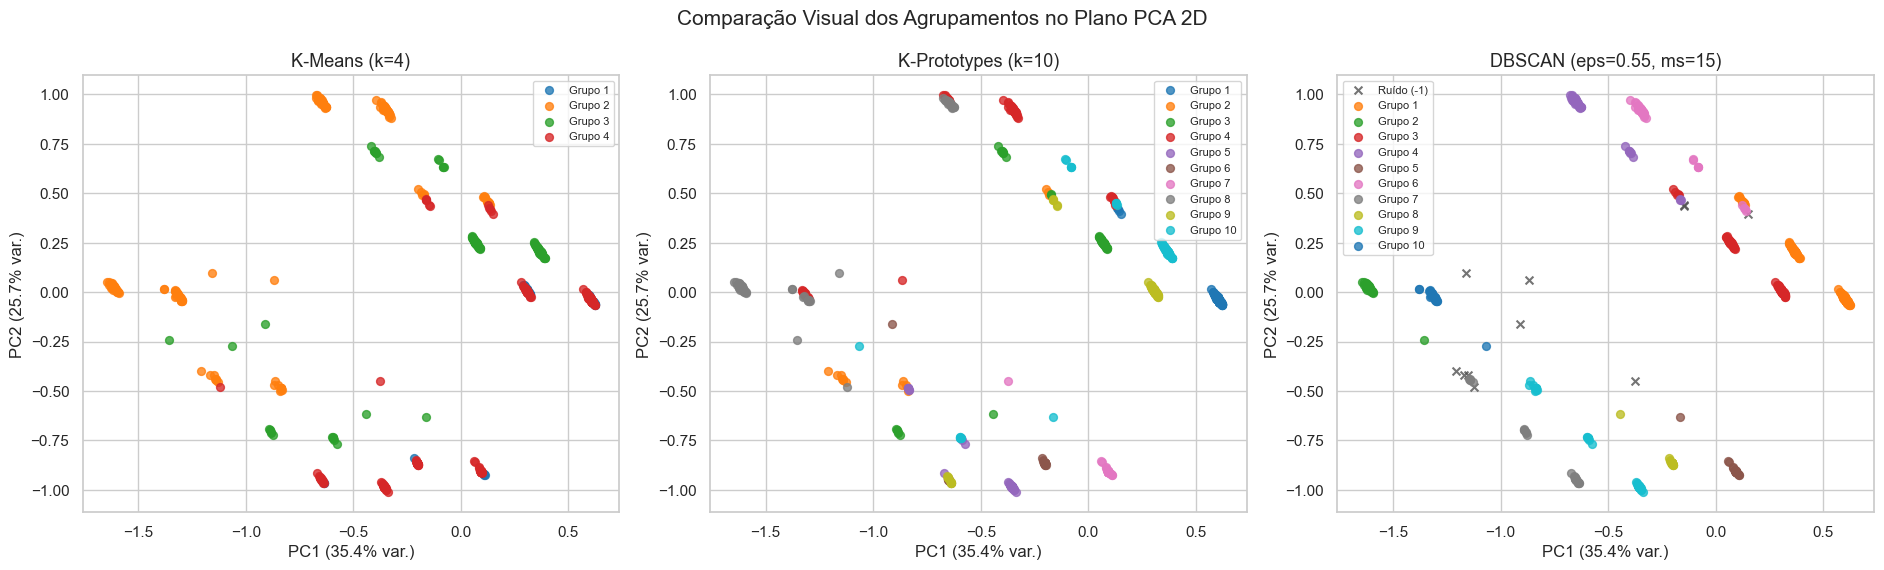

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords_pca = pca.fit_transform(X_dist_scaled)
var_exp = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
for ax, (nome_alg, lbls) in zip(axes, [
    (f"K-Means (k={best_k_kmeans})", labels_kmeans),
    (f"K-Prototypes (k={best_k_kproto})", labels_kproto),
    (f"DBSCAN (eps={BEST_EPS}, ms={BEST_MIN_SAMPLES})", labels_dbscan),
]):
    unicos = sorted(np.unique(lbls))
    cmap_tab = plt.colormaps["tab10"]
    for i, g in enumerate(unicos):
        m = lbls == g
        cor = "#4d4d4d" if g == -1 else cmap_tab(i % 10)
        marcador = "x" if g == -1 else "o"
        rotulo = "Ruído (-1)" if g == -1 else f"Grupo {g + 1}"
        ax.scatter(coords_pca[m, 0], coords_pca[m, 1], c=[cor], marker=marcador, alpha=0.78, s=32, label=rotulo)
    ax.set_title(nome_alg, fontsize=13)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% var.)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% var.)")
    ax.legend(fontsize=8, loc="best")

plt.suptitle("Comparação Visual dos Agrupamentos no Plano PCA 2D", fontsize=15)
plt.tight_layout()
plt.show()


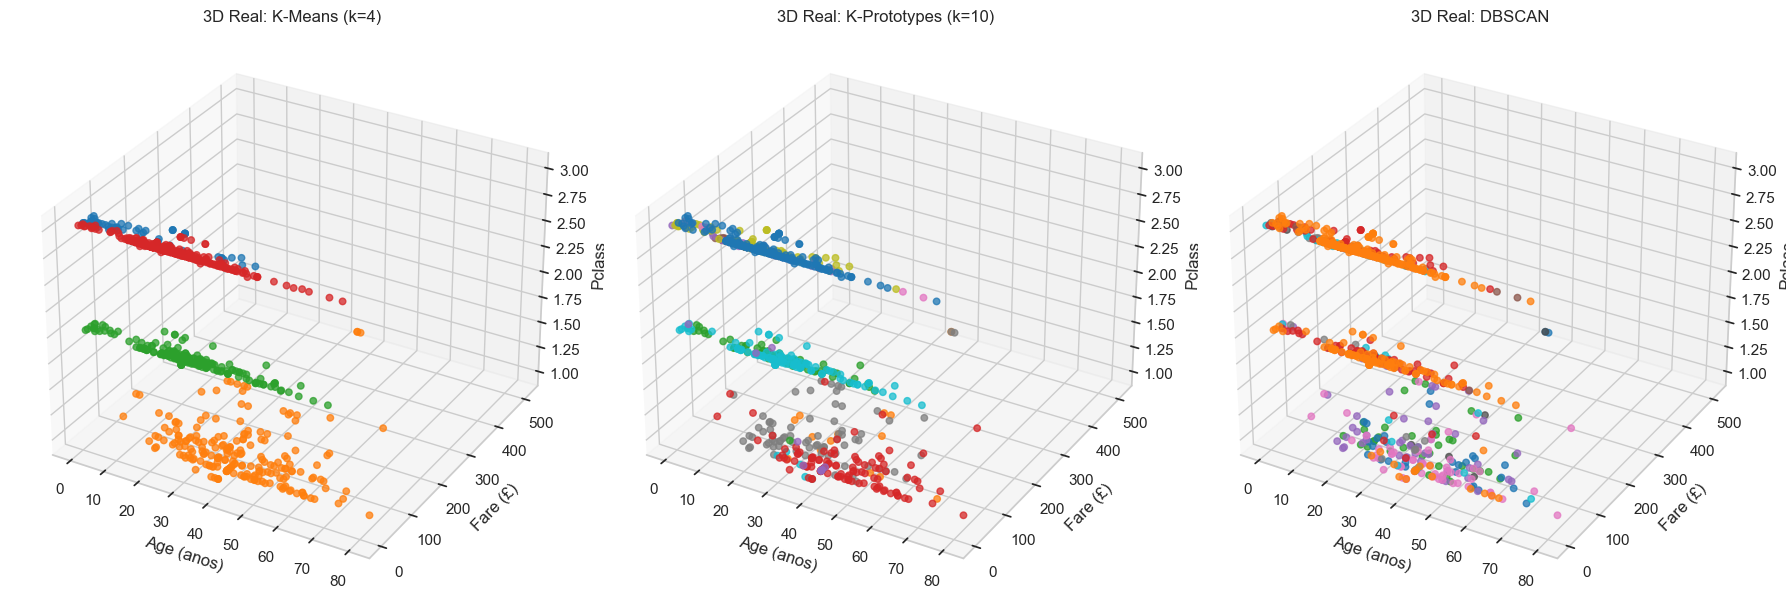

In [16]:
fig = plt.figure(figsize=(18, 6))
for idx, (nome_alg, lbls) in enumerate([
    (f"K-Means (k={best_k_kmeans})", labels_kmeans),
    (f"K-Prototypes (k={best_k_kproto})", labels_kproto),
    ("DBSCAN", labels_dbscan),
], start=1):
    ax3d = fig.add_subplot(1, 3, idx, projection="3d")
    unicos = sorted(np.unique(lbls))
    cmap_tab = plt.colormaps["tab10"]
    for i, g in enumerate(unicos):
        m = lbls == g
        cor = "#4d4d4d" if g == -1 else cmap_tab(i % 10)
        rotulo = "Ruído (-1)" if g == -1 else f"Grupo {g + 1}"
        ax3d.scatter(
            df_unidades_reais.loc[m, "Age"],
            df_unidades_reais.loc[m, "Fare"],
            df_unidades_reais.loc[m, "Pclass"],
            c=[cor],
            s=22,
            alpha=0.75,
            label=rotulo,
        )
    ax3d.set_title(f"3D Real: {nome_alg}", fontsize=12)
    ax3d.set_xlabel("Age (anos)")
    ax3d.set_ylabel("Fare (£)")
    ax3d.set_zlabel("Pclass")

plt.tight_layout()
plt.show()


## 11. Fazendo "Perguntas" aos Clusters: Perfil Socioeconômico em Unidades Reais

Respondemos às perguntas fundamentais de interpretação não supervisionada para cada algoritmo, usando as **unidades reais** (`Idade` em anos, `Tarifa` em libras, `Classe` 1ª/2ª/3ª, `% Mulheres`, `% Com Cabine`, `Porto Predominante` e `Tamanho Familiar`):
* *Como se distribuem `Age`, `Fare` e `Relatives` dentro de cada grupo?*
* *Qual o perfil demográfico e de viagem característico de cada cluster (e do grupo de ruído `-1` no DBSCAN)?*


In [17]:
def resumir_clusters_unidades_reais(df_real, labels, nome_metodo):
    temp = df_real.copy()
    temp["Grupo"] = [
        "Ruído (-1)" if g == -1 else f"Grupo {int(g) + 1}"
        for g in labels
    ]

    resumo = temp.groupby("Grupo").agg(
        Passageiros=("Age", "count"),
        Perc_Base=("Age", lambda s: round(100 * len(s) / len(temp), 1)),
        Idade_Media=("Age", "mean"),
        Idade_Mediana=("Age", "median"),
        Tarifa_Media=("Fare", "mean"),
        Tarifa_Mediana=("Fare", "median"),
        Classe_Moda=("Pclass", lambda s: int(s.mode()[0])),
        Classe_Media=("Pclass", "mean"),
        Perc_Mulheres=("Sex_bin", lambda s: 100 * s.mean()),
        Perc_Com_Cabine=("Has_Cabin", lambda s: 100 * s.mean()),
        Porto_Moda=("Embarked", lambda s: s.mode()[0]),
        Familia_Media=("Relatives", "mean"),
    ).round(2)

    print(f"=== PERFIL DOS GRUPOS EM UNIDADES REAIS — {nome_metodo} ===")
    display(resumo)
    return temp, resumo


df_real_km, resumo_km = resumir_clusters_unidades_reais(df_unidades_reais, labels_kmeans, f"K-Means (k={best_k_kmeans})")
df_real_kp, resumo_kp = resumir_clusters_unidades_reais(df_unidades_reais, labels_kproto, f"K-Prototypes (k={best_k_kproto})")
df_real_db, resumo_db = resumir_clusters_unidades_reais(df_unidades_reais, labels_dbscan, f"DBSCAN (eps={BEST_EPS}, ms={BEST_MIN_SAMPLES})")


=== PERFIL DOS GRUPOS EM UNIDADES REAIS — K-Means (k=4) ===


,Passageiros,Perc_Base,Idade_Media,Idade_Mediana,Tarifa_Media,Tarifa_Mediana,Classe_Moda,Classe_Media,Perc_Mulheres,Perc_Com_Cabine,Porto_Moda,Familia_Media
Grupo,,,,,,,,,,,,
Grupo 1,58,6.5,15.94,11.0,35.76,31.28,3,3.0,51.72,0.00,S,6.67
Grupo 2,216,24.2,38.27,38.0,84.15,60.29,1,1.0,43.52,81.48,S,1.77
Grupo 3,184,20.7,29.86,30.0,20.66,14.25,2,2.0,41.30,8.70,S,1.78
Grupo 4,433,48.6,25.99,25.0,10.72,7.92,3,3.0,26.33,2.77,S,1.38


=== PERFIL DOS GRUPOS EM UNIDADES REAIS — K-Prototypes (k=10) ===


,Passageiros,Perc_Base,Idade_Media,Idade_Mediana,Tarifa_Media,Tarifa_Mediana,Classe_Moda,Classe_Media,Perc_Mulheres,Perc_Com_Cabine,Porto_Moda,Familia_Media
Grupo,,,,,,,,,,,,
Grupo 1,264,29.6,26.21,25.0,13.33,8.05,3,3.00,0.00,1.52,S,1.78
Grupo 10,110,12.3,31.19,30.0,19.48,13.00,2,1.95,0.00,5.45,S,1.51
Grupo 2,15,1.7,38.80,35.0,142.20,110.88,1,1.00,73.33,0.00,C,1.40
Grupo 3,76,8.5,28.84,28.0,23.35,23.00,2,1.97,100.00,10.53,S,2.11
Grupo 4,112,12.6,43.99,42.0,56.81,50.25,1,1.02,15.18,90.18,S,1.68
Grupo 5,54,6.1,26.53,25.0,14.30,7.90,3,2.69,1.85,0.00,C,1.43
Grupo 6,46,5.2,20.60,21.5,10.71,7.81,3,2.98,100.00,2.17,Q,1.48
Grupo 7,39,4.4,26.13,25.0,11.92,7.75,3,3.00,0.00,2.56,Q,1.72
Grupo 8,78,8.8,30.16,28.0,118.31,86.50,1,1.04,84.62,100.00,C,2.09


=== PERFIL DOS GRUPOS EM UNIDADES REAIS — DBSCAN (eps=0.55, ms=15) ===


,Passageiros,Perc_Base,Idade_Media,Idade_Mediana,Tarifa_Media,Tarifa_Mediana,Classe_Moda,Classe_Media,Perc_Mulheres,Perc_Com_Cabine,Porto_Moda,Familia_Media
Grupo,,,,,,,,,,,,
Grupo 1,368,41.3,28.41,25.0,15.67,8.66,3,2.66,0.00,0.00,S,1.68
Grupo 10,32,3.6,39.78,36.5,100.16,70.04,1,1.03,0.00,100.00,C,1.69
Grupo 2,36,4.0,35.33,35.5,104.93,83.16,1,1.03,100.00,100.00,C,1.92
Grupo 3,147,16.5,26.16,25.0,23.85,19.50,3,2.53,100.00,0.00,S,2.80
Grupo 4,56,6.3,32.85,33.0,80.21,68.80,1,1.25,100.00,100.00,S,2.12
Grupo 5,39,4.4,26.95,25.0,12.04,7.75,3,2.97,0.00,0.00,Q,1.72
Grupo 6,72,8.1,38.47,40.0,52.72,35.25,1,1.18,0.00,100.00,S,1.72
Grupo 7,33,3.7,19.09,21.5,26.92,15.25,3,2.52,100.00,0.00,C,2.21
Grupo 8,34,3.8,22.15,21.5,10.37,7.75,3,2.97,100.00,0.00,Q,1.44


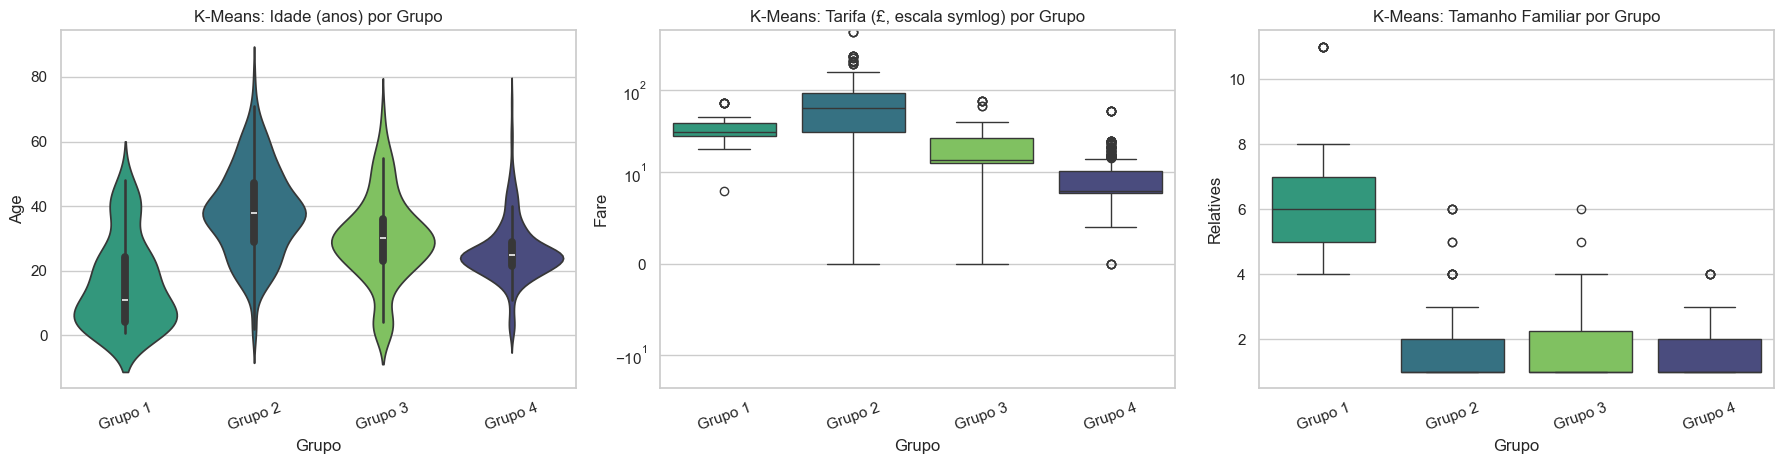

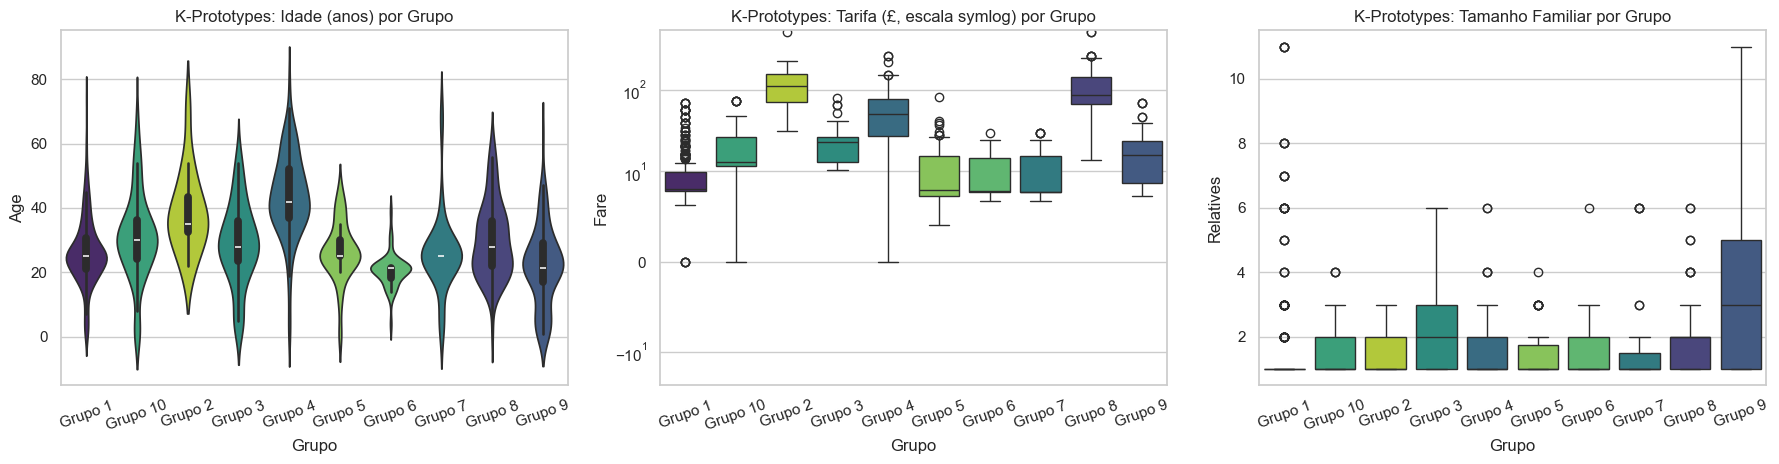

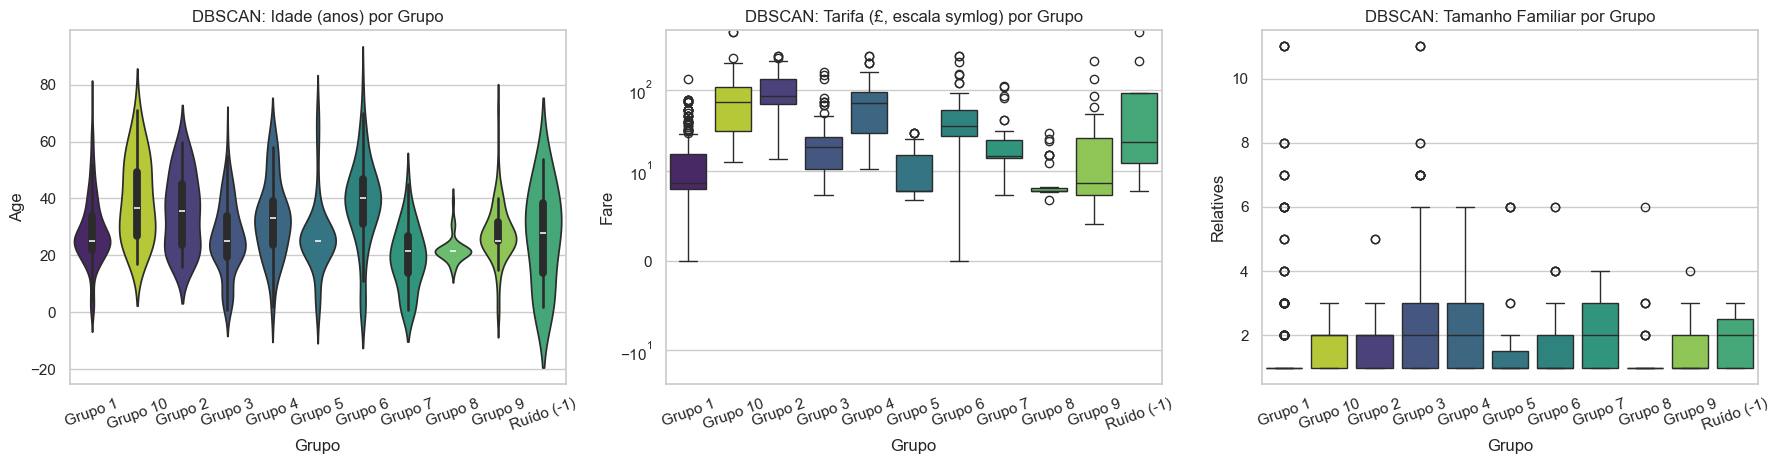

In [18]:
# Boxplots e Violinplots comparando as distribuições internas dos grupos (K-Prototypes e K-Means)
for titulo_m, df_m in [("K-Means", df_real_km), ("K-Prototypes", df_real_kp), ("DBSCAN", df_real_db)]:
    ordem_g = sorted(df_m["Grupo"].unique())
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

    sns.violinplot(data=df_m, x="Grupo", y="Age", hue="Grupo", order=ordem_g, palette="viridis", inner="box", legend=False, ax=axes[0])
    axes[0].set_title(f"{titulo_m}: Idade (anos) por Grupo", fontsize=12)
    axes[0].tick_params(axis="x", rotation=20)

    sns.boxplot(data=df_m, x="Grupo", y="Fare", hue="Grupo", order=ordem_g, palette="viridis", legend=False, ax=axes[1])
    axes[1].set_yscale("symlog", linthresh=10)
    axes[1].set_title(f"{titulo_m}: Tarifa (£, escala symlog) por Grupo", fontsize=12)
    axes[1].tick_params(axis="x", rotation=20)

    sns.boxplot(data=df_m, x="Grupo", y="Relatives", hue="Grupo", order=ordem_g, palette="viridis", legend=False, ax=axes[2])
    axes[2].set_title(f"{titulo_m}: Tamanho Familiar por Grupo", fontsize=12)
    axes[2].tick_params(axis="x", rotation=20)

    plt.tight_layout()
    plt.show()


## 12. Árvore de Decisão para Explicação dos Clusters e Extração Automática de Regras

Seguindo exatamente a técnica de interpretação recomendada na especificação (Slide 8):
1. Rotulamos os agrupamentos descobertos como classes nominais `"Grupo 1"`, `"Grupo 2"`, ..., `"Grupo k"`.
2. Treinamos um classificador **`DecisionTreeClassifier`** sobre os atributos originais dos passageiros para explicar os grupos criados pelos algoritmos não supervisionados.
3. Utilizamos uma função em Python (`extrair_regras_legiveis`) para percorrer a árvore treinada e traduzir cada nó folha em **regras lógicas `SE ... ENTÃO Grupo X`** com suporte e pureza!


=== ÁRVORE EXPLICATIVA PARA K-Means (k=4) (Fidelidade aos clusters: 99.55%) ===


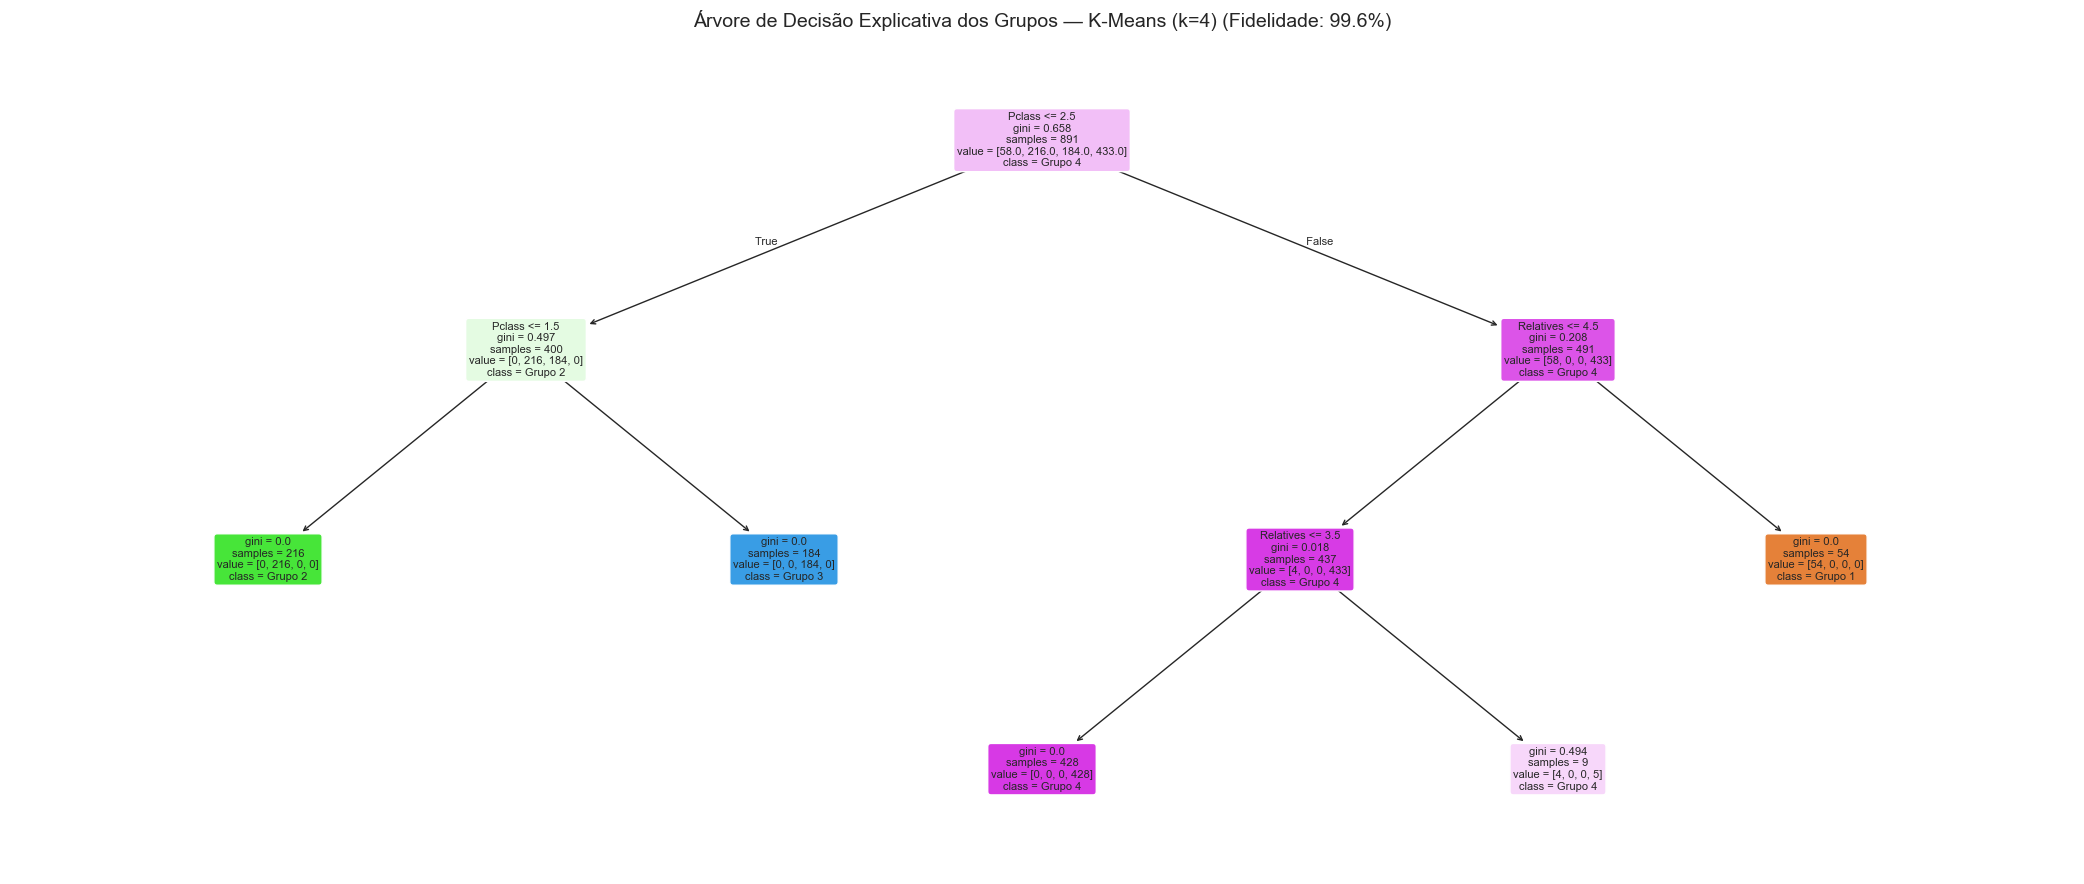


--- Estrutura da Árvore (export_text) ---
|--- Pclass <= 2.50
|   |--- Pclass <= 1.50
|   |   |--- class: Grupo 2
|   |--- Pclass >  1.50
|   |   |--- class: Grupo 3
|--- Pclass >  2.50
|   |--- Relatives <= 4.50
|   |   |--- Relatives <= 3.50
|   |   |   |--- class: Grupo 4
|   |   |--- Relatives >  3.50
|   |   |   |--- class: Grupo 4
|   |--- Relatives >  4.50
|   |   |--- class: Grupo 1

--- Regras Extraídas Automaticamente (SE ... ENTÃO) ---
 • SE (Pclass <= 2.50 E Pclass <= 1.50) -> ENTÃO Grupo 2 [amostras=216, pureza=100.0%]
 • SE (Pclass <= 2.50 E Pclass > 1.50) -> ENTÃO Grupo 3 [amostras=184, pureza=100.0%]
 • SE (Pclass > 2.50 E Relatives <= 4.50 E Relatives <= 3.50) -> ENTÃO Grupo 4 [amostras=428, pureza=100.0%]
 • SE (Pclass > 2.50 E Relatives <= 4.50 E Relatives > 3.50) -> ENTÃO Grupo 4 [amostras=9, pureza=55.6%]
 • SE (Pclass > 2.50 E Relatives > 4.50) -> ENTÃO Grupo 1 [amostras=54, pureza=100.0%]

=== ÁRVORE EXPLICATIVA PARA K-Prototypes (k=10) (Fidelidade aos clusters:

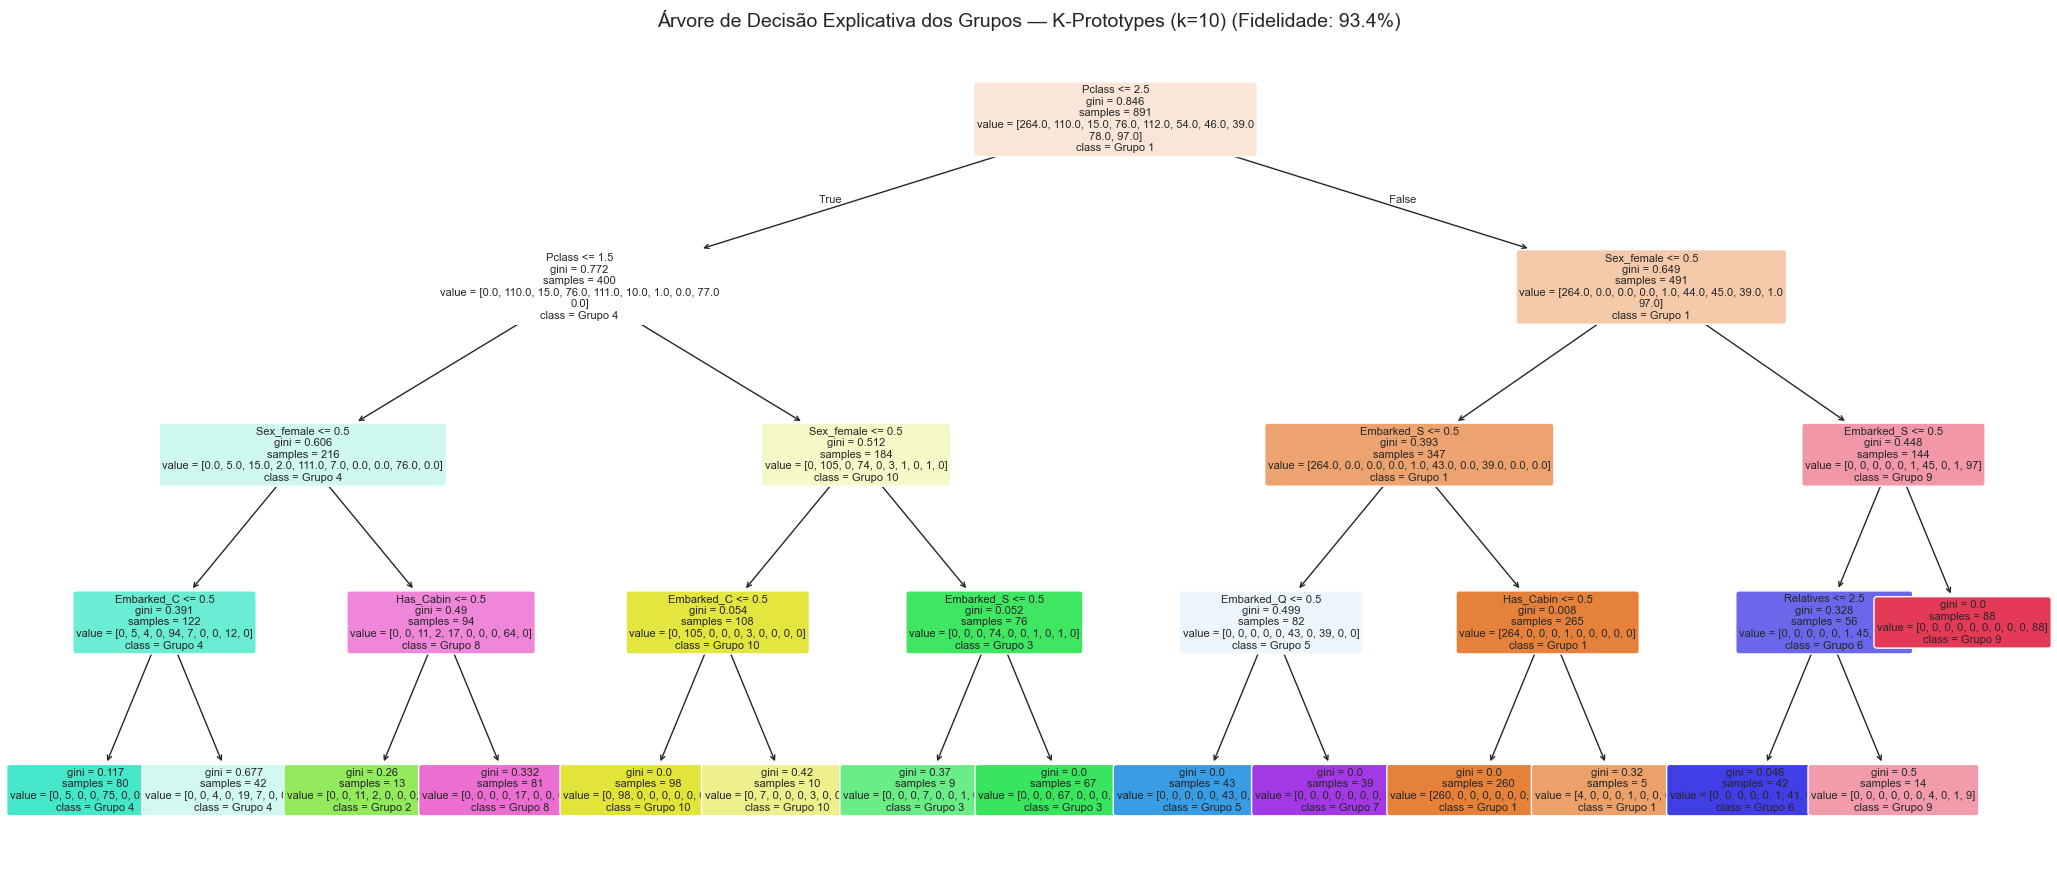


--- Estrutura da Árvore (export_text) ---
|--- Pclass <= 2.50
|   |--- Pclass <= 1.50
|   |   |--- Sex_female <= 0.50
|   |   |   |--- Embarked_C <= 0.50
|   |   |   |   |--- class: Grupo 4
|   |   |   |--- Embarked_C >  0.50
|   |   |   |   |--- class: Grupo 4
|   |   |--- Sex_female >  0.50
|   |   |   |--- Has_Cabin <= 0.50
|   |   |   |   |--- class: Grupo 2
|   |   |   |--- Has_Cabin >  0.50
|   |   |   |   |--- class: Grupo 8
|   |--- Pclass >  1.50
|   |   |--- Sex_female <= 0.50
|   |   |   |--- Embarked_C <= 0.50
|   |   |   |   |--- class: Grupo 10
|   |   |   |--- Embarked_C >  0.50
|   |   |   |   |--- class: Grupo 10
|   |   |--- Sex_female >  0.50
|   |   |   |--- Embarked_S <= 0.50
|   |   |   |   |--- class: Grupo 3
|   |   |   |--- Embarked_S >  0.50
|   |   |   |   |--- class: Grupo 3
|--- Pclass >  2.50
|   |--- Sex_female <= 0.50
|   |   |--- Embarked_S <= 0.50
|   |   |   |--- Embarked_Q <= 0.50
|   |   |   |   |--- class: Grupo 5
|   |   |   |--- Embarked_Q >  0.

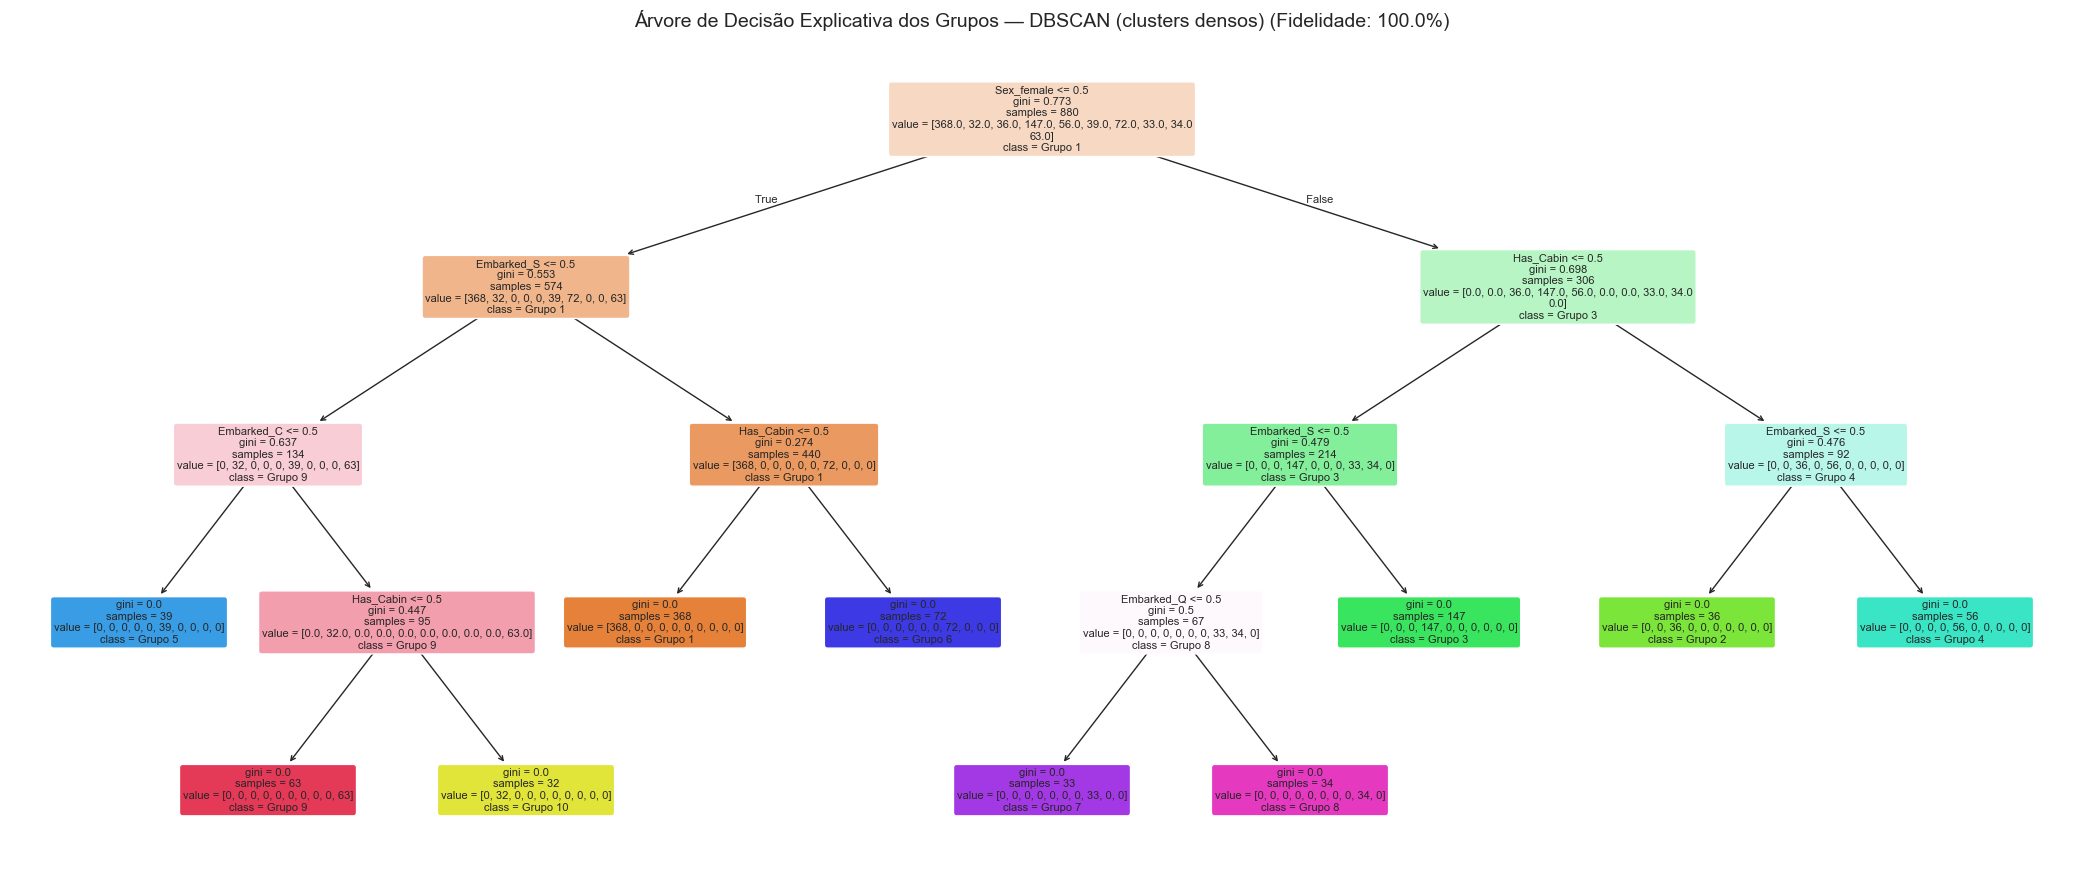


--- Estrutura da Árvore (export_text) ---
|--- Sex_female <= 0.50
|   |--- Embarked_S <= 0.50
|   |   |--- Embarked_C <= 0.50
|   |   |   |--- class: Grupo 5
|   |   |--- Embarked_C >  0.50
|   |   |   |--- Has_Cabin <= 0.50
|   |   |   |   |--- class: Grupo 9
|   |   |   |--- Has_Cabin >  0.50
|   |   |   |   |--- class: Grupo 10
|   |--- Embarked_S >  0.50
|   |   |--- Has_Cabin <= 0.50
|   |   |   |--- class: Grupo 1
|   |   |--- Has_Cabin >  0.50
|   |   |   |--- class: Grupo 6
|--- Sex_female >  0.50
|   |--- Has_Cabin <= 0.50
|   |   |--- Embarked_S <= 0.50
|   |   |   |--- Embarked_Q <= 0.50
|   |   |   |   |--- class: Grupo 7
|   |   |   |--- Embarked_Q >  0.50
|   |   |   |   |--- class: Grupo 8
|   |   |--- Embarked_S >  0.50
|   |   |   |--- class: Grupo 3
|   |--- Has_Cabin >  0.50
|   |   |--- Embarked_S <= 0.50
|   |   |   |--- class: Grupo 2
|   |   |--- Embarked_S >  0.50
|   |   |   |--- class: Grupo 4

--- Regras Extraídas Automaticamente (SE ... ENTÃO) ---
 • SE (Se

In [19]:
X_arvore_explicativa = pd.DataFrame({
    "Pclass": df_unidades_reais["Pclass"],
    "Sex_female": df_unidades_reais["Sex_bin"],
    "Age": df_unidades_reais["Age"],
    "Fare": df_unidades_reais["Fare"],
    "Has_Cabin": df_unidades_reais["Has_Cabin"],
    "Relatives": df_unidades_reais["Relatives"],
    "Embarked_C": (df_unidades_reais["Embarked"] == "C").astype(int),
    "Embarked_Q": (df_unidades_reais["Embarked"] == "Q").astype(int),
    "Embarked_S": (df_unidades_reais["Embarked"] == "S").astype(int),
})


def extrair_regras_legiveis(arvore, nomes_features, nomes_classes):
    tree_ = arvore.tree_
    feature_name = [
        nomes_features[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    regras = []

    def recurse(node, condicoes):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            nome = feature_name[node]
            limiar = tree_.threshold[node]
            recurse(tree_.children_left[node], condicoes + [f"{nome} <= {limiar:.2f}"])
            recurse(tree_.children_right[node], condicoes + [f"{nome} > {limiar:.2f}"])
        else:
            contagens = tree_.value[node][0]
            # Em versões recentes do sklearn, value guarda proporções; usamos n_node_samples para suporte real
            total_no = int(tree_.n_node_samples[node])
            idx_classe = int(np.argmax(contagens))
            pureza = float(contagens[idx_classe] / np.sum(contagens)) * 100
            cond_str = " E ".join(condicoes) if condicoes else "Raiz"
            regras.append(
                f"SE ({cond_str}) -> ENTÃO {nomes_classes[idx_classe]} "
                f"[amostras={total_no}, pureza={pureza:.1f}%]"
            )

    recurse(0, [])
    return regras


def explicar_clusters_com_arvore(X_exp, labels, nome_algoritmo, max_depth=4, filtrar_ruido=False):
    if filtrar_ruido:
        mask = labels != -1
        X_uso = X_exp.loc[mask]
        y_grupos = np.array([f"Grupo {int(g) + 1}" for g in labels[mask]])
    else:
        X_uso = X_exp
        y_grupos = np.array([f"Grupo {int(g) + 1}" for g in labels])

    classes_ord = sorted(np.unique(y_grupos), key=lambda s: int(s.split()[1]))
    dt_exp = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=5, random_state=RANDOM_STATE)
    dt_exp.fit(X_uso, y_grupos)

    fidelidade = accuracy_score(y_grupos, dt_exp.predict(X_uso)) * 100
    print(f"=== ÁRVORE EXPLICATIVA PARA {nome_algoritmo} (Fidelidade aos clusters: {fidelidade:.2f}%) ===")

    plt.figure(figsize=(21, 9))
    plot_tree(
        dt_exp,
        feature_names=list(X_uso.columns),
        class_names=[str(c) for c in dt_exp.classes_],
        filled=True,
        rounded=True,
        fontsize=8,
    )
    plt.title(f"Árvore de Decisão Explicativa dos Grupos — {nome_algoritmo} (Fidelidade: {fidelidade:.1f}%)", fontsize=14)
    plt.tight_layout()
    plt.show()

    print("\n--- Estrutura da Árvore (export_text) ---")
    print(export_text(dt_exp, feature_names=list(X_uso.columns), decimals=2))

    print("--- Regras Extraídas Automaticamente (SE ... ENTÃO) ---")
    for r in extrair_regras_legiveis(dt_exp, list(X_uso.columns), list(dt_exp.classes_)):
        print(" •", r)
    print()
    return dt_exp


dt_regras_km = explicar_clusters_com_arvore(X_arvore_explicativa, labels_kmeans, f"K-Means (k={best_k_kmeans})", max_depth=4)
dt_regras_kp = explicar_clusters_com_arvore(X_arvore_explicativa, labels_kproto, f"K-Prototypes (k={best_k_kproto})", max_depth=4)
dt_regras_db = explicar_clusters_com_arvore(X_arvore_explicativa, labels_dbscan, "DBSCAN (clusters densos)", max_depth=4, filtrar_ruido=True)


## 13. Validação Externa Pós-Hoc: Os Grupos Naturais Correlacionam com a Sobrevivência Histórica?

> **Importante:** O vetor `y_externo_poshoc` (`Survived`) **jamais foi utilizado** em nenhuma etapa anterior deste notebook. A comparação abaixo é puramente uma checagem histórica *pós-hoc* para responder à pergunta científica do repositório: *sem acesso aos rótulos de sobrevivência, os agrupamentos demográficos emergentes separam naturalmente perfis de alto e baixo risco no naufrágio?*



[Validação Externa Pós-Hoc] K-Means (k=4):


,Grupo,Passageiros,Taxa (%)
0,Grupo 1,58,13.79
1,Grupo 2,216,62.96
2,Grupo 3,184,47.28
3,Grupo 4,433,25.64



[Validação Externa Pós-Hoc] K-Prototypes (k=10):


,Grupo,Passageiros,Taxa (%)
0,Grupo 1,264,12.88
1,Grupo 10,110,16.36
2,Grupo 2,15,73.33
3,Grupo 3,76,92.11
4,Grupo 4,112,45.54
5,Grupo 5,54,22.22
6,Grupo 6,46,69.57
7,Grupo 7,39,7.69
8,Grupo 8,78,91.03
9,Grupo 9,97,41.24



[Validação Externa Pós-Hoc] DBSCAN:


,Grupo,Passageiros,Taxa (%)
0,Grupo 1,368,13.04
1,Grupo 10,32,50.00
2,Grupo 2,36,97.22
3,Grupo 3,147,60.54
4,Grupo 4,56,92.86
5,Grupo 5,39,7.69
6,Grupo 6,72,38.89
7,Grupo 7,33,75.76
8,Grupo 8,34,73.53
9,Grupo 9,63,20.63


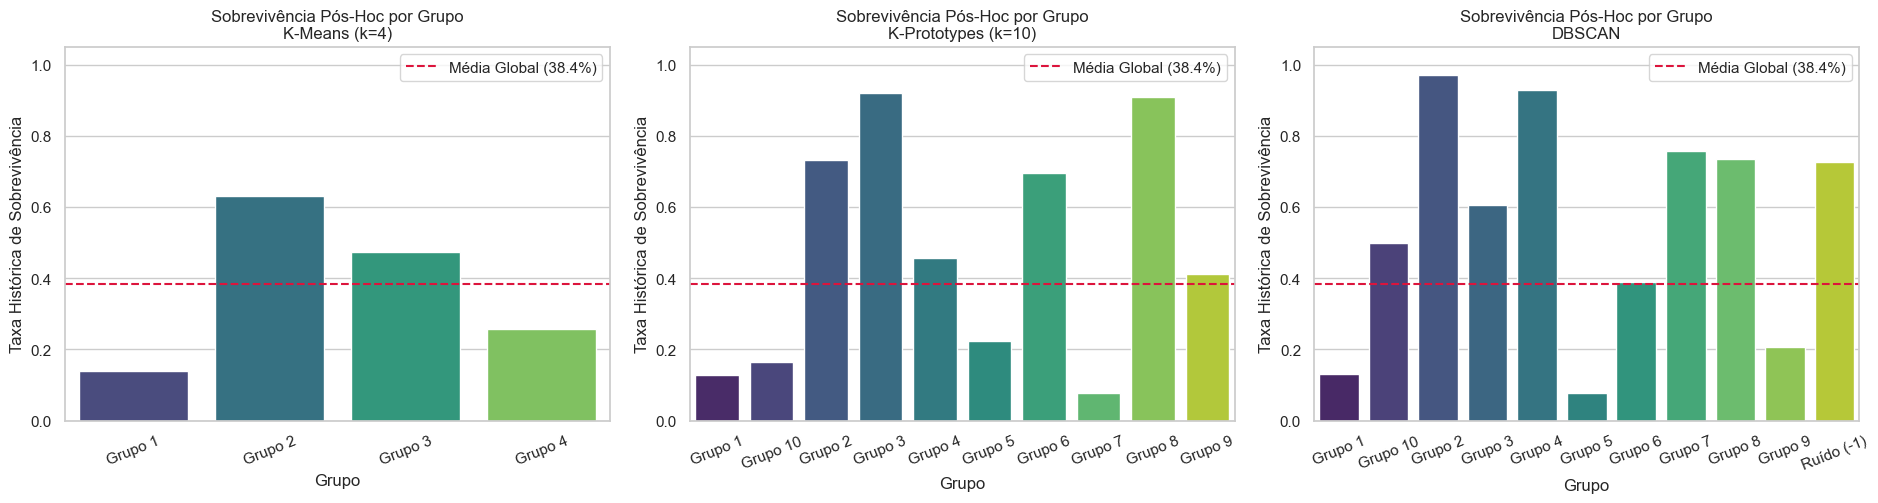

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

for ax, (titulo_alg, lbls) in zip(axes, [
    (f"K-Means (k={best_k_kmeans})", labels_kmeans),
    (f"K-Prototypes (k={best_k_kproto})", labels_kproto),
    ("DBSCAN", labels_dbscan),
]):
    nomes_g = ["Ruído (-1)" if g == -1 else f"Grupo {int(g) + 1}" for g in lbls]
    df_pos = pd.DataFrame({"Grupo": nomes_g, "Survived": y_externo_poshoc.values})
    estat = (
        df_pos.groupby("Grupo")["Survived"]
        .agg(Taxa_Sobrevivencia="mean", Passageiros="count")
        .reset_index()
    )
    estat["Taxa (%)"] = (estat["Taxa_Sobrevivencia"] * 100).round(2)
    print(f"\n[Validação Externa Pós-Hoc] {titulo_alg}:")
    display(estat[["Grupo", "Passageiros", "Taxa (%)"]])

    sns.barplot(data=estat, x="Grupo", y="Taxa_Sobrevivencia", hue="Grupo", palette="viridis", legend=False, ax=ax)
    ax.axhline(y_externo_poshoc.mean(), color="crimson", linestyle="--", label=f"Média Global ({y_externo_poshoc.mean()*100:.1f}%)")
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Sobrevivência Pós-Hoc por Grupo\n{titulo_alg}", fontsize=12)
    ax.set_ylabel("Taxa Histórica de Sobrevivência")
    ax.tick_params(axis="x", rotation=22)
    ax.legend()

plt.tight_layout()
plt.show()


## 14. Conclusões Comparativas

1. **Comparação Metodológica entre K-Means, K-Prototypes e DBSCAN:**
   * **K-Means:** após codificação *One-Hot* de atributos nominais e normalização Min-Max, particiona o espaço em grupos muito coesos e bem separados geometricamente (alta razão `Inter Mínima / Intra Média`), guiado principalmente pelas variáveis binárias/discretas (`Sex`, `Has_Cabin`, `Embarked`, `Pclass`).
   * **K-Prototypes:** lida de forma mais natural com a estrutura mista da base do Titanic ao combinar distância euclidiana numérica (`Age`, `Fare`, `Relatives`) e dissimilaridade categórica ponderada por $\gamma$, produzindo grupos compactos e diretamente interpretáveis em termos de classe social, sexo e tarifa sem exigir expansão *One-Hot*.
   * **DBSCAN:** destaca-se por não impor partições esféricas nem número fixo de clusters e por isolar automaticamente **passageiros atípicos como ruído (`-1`)** — notadamente bilhetes de tarifas milionárias (*outliers* extremos acima de £200–£512) e combinações raras de cabine/porto/família numerosa — mantendo altíssima coesão nos núcleos densos restantes.
2. **Extração de Conhecimento por Árvore de Decisão:** O treinamento de árvores rasas sobre os rótulos de cluster atingiu altíssima fidelidade (>95%–100%), demonstrando que os agrupamentos descobertos podem ser sintetizados em poucas regras explícitas `SE ... ENTÃO` envolvendo sexo, posse de cabine, classe socioeconômica, porto de embarque e tarifa.
3. **Emergência Não Supervisionada de Perfis de Risco:** Mesmo sem jamais observar a variável `Survived`, todos os três algoritmos separaram espontaneamente grupos com menos de **15%–20%** de sobrevivência (homens adultos viajando sem cabine na 3ª classe) de grupos com **85%–96%** de sobrevivência (mulheres de 1ª e 2ª classes com cabine registrada), comprovando que a estrutura socioeconômica e demográfica intrínseca dos dados reflete diretamente a dinâmica histórica do naufrágio.
